# Final Model — DenseNet121 + MedMamba Adaptive Gated Fusion
### NIH ChestX-ray14 | Existing trained checkpoints → 1024-D + 512-D → Gated Fusion → 14 labels

This version is adapted from the supplied `baseline1.ipynb`, `baseline2.ipynb`, and `fusionmodel.ipynb`.

**What it does**
1. Uses the already-trained **DenseNet121 branch** from `best_dual_branch_model.pt`.
2. Uses the already-trained **real MedMamba VSSM** from `best_medmamba_checkpoint.pth`.
3. Extracts their features for the same patient-wise 70/15/15 split.
4. Aligns both branches by image ID.
5. Trains only the **projection + adaptive gate + 14-class classifier**.
6. Saves the final fusion checkpoint and evaluation results.

**Important:** This does NOT train DenseNet121 or MedMamba from scratch again.


## 1. Paths

Change only the two checkpoint paths if your files are stored elsewhere.

The paths below match the files shown in your JupyterHub screenshot.


In [1]:

from pathlib import Path
import os, sys, glob, time, random, warnings, subprocess, importlib.util
warnings.filterwarnings("ignore")

# ============================================================
# EDIT THESE ONLY IF YOUR CHECKPOINTS ARE IN A DIFFERENT PATH
# ============================================================
DENSENET_CHECKPOINT = Path("best_dual_branch_model.pt")
MEDMAMBA_CHECKPOINT = Path("best_medmamba_checkpoint.pth")

OUTPUT_DIR = Path("./final_fusion_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DENSENET_FEATURE_FILE = OUTPUT_DIR / "baseline1_densenet_features.pt"
MEDMAMBA_FEATURE_FILE = OUTPUT_DIR / "baseline2_medmamba_features.pt"
CHECKPOINT_FILE = OUTPUT_DIR / "best_adaptive_gated_fusion.pt"

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 128
FEATURE_BATCH_SIZE = 256
NUM_WORKERS = 8

EPOCHS = 30
FUSION_BATCH_SIZE = 4096
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 6

DENSE_DIM = 1024
MAMBA_DIM = 512
PROJ_DIM = 256
NUM_CLASSES = 14
THRESHOLD = 0.50

DISEASES = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural_Thickening", "Hernia"
]

assert len(DISEASES) == NUM_CLASSES

random.seed(SEED)
import numpy as np
np.random.seed(SEED)

print("DenseNet checkpoint:", DENSENET_CHECKPOINT)
print("MedMamba checkpoint:", MEDMAMBA_CHECKPOINT)
print("Output directory   :", OUTPUT_DIR)


DenseNet checkpoint: best_dual_branch_model.pt
MedMamba checkpoint: best_medmamba_checkpoint.pth
Output directory   : final_fusion_results


## 2. GPU and packages

In [2]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import cv2

from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms, models
from PIL import Image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          torch.cuda.get_device_properties(0).total_memory / (1024**3))
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    if hasattr(torch, "set_float32_matmul_precision"):
        torch.set_float32_matmul_precision("high")


PyTorch: 2.13.0+cu130
CUDA: True
Device: cuda
GPU: NVIDIA H200 NVL
GPU memory (GB): 139.80072021484375


## 3. Download/load the same NIH ChestX-ray14 dataset and recreate the baseline split

In [3]:

import kagglehub

downloaded_path = kagglehub.dataset_download(
    "khanfashee/nih-chest-x-ray-14-224x224-resized"
)
DATA_ROOT = Path(downloaded_path)

expected_csv = DATA_ROOT / "Data_Entry_2017.csv"
expected_img_dir = DATA_ROOT / "images-224" / "images-224"

if expected_csv.exists() and expected_img_dir.is_dir():
    LABELS_CSV = expected_csv
    image_files = glob.glob(str(expected_img_dir / "*.png"))
else:
    csv_candidates = sorted(set(
        glob.glob(str(DATA_ROOT / "**" / "*Data_Entry*.csv"), recursive=True)
        + glob.glob(str(DATA_ROOT / "**" / "*.csv"), recursive=True)
    ))
    if not csv_candidates:
        raise FileNotFoundError("Could not find NIH metadata CSV.")
    LABELS_CSV = Path(csv_candidates[0])
    image_files = (
        glob.glob(str(DATA_ROOT / "**" / "*.png"), recursive=True)
        + glob.glob(str(DATA_ROOT / "**" / "*.jpg"), recursive=True)
    )

IMAGE_INDEX = {os.path.basename(p): p for p in image_files}

df = pd.read_csv(LABELS_CSV)
df.columns = [c.strip() for c in df.columns]

image_col = "Image Index" if "Image Index" in df.columns else df.columns[0]
label_col = "Finding Labels" if "Finding Labels" in df.columns else df.columns[1]
patient_col = "Patient ID" if "Patient ID" in df.columns else None

df["filepath"] = df[image_col].map(IMAGE_INDEX)
df = df[df["filepath"].notna()].reset_index(drop=True)

def to_multihot(label_str):
    vec = np.zeros(NUM_CLASSES, dtype=np.float32)
    for label in str(label_str).split("|"):
        label = label.strip()
        if label in DISEASES:
            vec[DISEASES.index(label)] = 1.0
    return vec

label_matrix = np.stack(df[label_col].map(to_multihot).values)
for i, disease in enumerate(DISEASES):
    df[disease] = label_matrix[:, i]

from sklearn.model_selection import GroupShuffleSplit

groups = df[patient_col] if patient_col else df[image_col]

g1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(g1.split(df, groups=groups))

temp_df = df.iloc[temp_idx].reset_index(drop=True)
temp_groups = temp_df[patient_col] if patient_col else temp_df[image_col]

g2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_rel, test_rel = next(g2.split(temp_df, groups=temp_groups))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = temp_df.iloc[val_rel].reset_index(drop=True)
test_df = temp_df.iloc[test_rel].reset_index(drop=True)

print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))
print("Total:", len(df))


Train: 78566
Val  : 16106
Test : 17448
Total: 112120


## 4. Exact preprocessing used by the supplied baselines

In [4]:

def clahe_unsharp(img):
    if img is None:
        raise ValueError("OpenCV could not read image.")
    if img.ndim == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    blurred = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=3)
    sharpened = cv2.addWeighted(enhanced, 1.5, blurred, -0.5, 0)
    return cv2.cvtColor(sharpened, cv2.COLOR_GRAY2BGR)

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["filepath"])
        img = clahe_unsharp(img)
        img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        img = eval_transform(img)
        label = row[DISEASES].values.astype(np.float32)
        return img, torch.tensor(label), str(row[image_col])

full_ds = ChestXrayDataset(df)
full_loader = DataLoader(
    full_ds, batch_size=FEATURE_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

print("Feature extraction samples:", len(full_ds))


Feature extraction samples: 112120


## 5. Load the trained DenseNet121 branch from `best_dual_branch_model.pt`

`baseline1.ipynb` saved a complete `DualBranchChestXray` state dict. We reconstruct the same architecture and take only its trained DenseNet121 branch.

The resulting feature is **1024-D**.


In [5]:
# DenseNet121 branch definition copied from baseline1 architecture.
# This must be defined before the checkpoint-loading cell.
class DenseNetBranch(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        base = models.densenet121(
            weights="IMAGENET1K_V1" if pretrained else None
        )
        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = 1024

    def forward(self, x):
        f = self.features(x)
        f = F.relu(f, inplace=False)
        return self.pool(f).flatten(1)

print("DenseNetBranch defined. Output dimension:", DenseNetBranch(pretrained=False).out_dim)


DenseNetBranch defined. Output dimension: 1024


In [6]:
# Load only the DenseNet121 branch weights from baseline1's trained checkpoint.
dense_model = DenseNetBranch(pretrained=True).to(DEVICE)

if not DENSENET_CHECKPOINT.exists():
    raise FileNotFoundError(f"Missing DenseNet checkpoint: {DENSENET_CHECKPOINT}")

dense_ckpt = torch.load(
    DENSENET_CHECKPOINT, map_location="cpu", weights_only=False
)
dense_state = (
    dense_ckpt["model_state_dict"]
    if isinstance(dense_ckpt, dict) and "model_state_dict" in dense_ckpt
    else dense_ckpt
)

dense_branch_state = {
    k[len("densenet_branch."):]: v
    for k, v in dense_state.items()
    if k.startswith("densenet_branch.")
}

if not dense_branch_state:
    raise KeyError(
        "No 'densenet_branch.' weights were found in best_dual_branch_model.pt. "
        "This checkpoint may not be the baseline1 checkpoint expected by this notebook."
    )

missing, unexpected = dense_model.load_state_dict(dense_branch_state, strict=False)

if missing:
    raise RuntimeError(f"DenseNet branch is missing checkpoint weights: {missing[:10]}")
if unexpected:
    print("Unexpected DenseNet branch keys:", unexpected[:10])

dense_model.eval()
for p in dense_model.parameters():
    p.requires_grad = False

print("DenseNet branch loaded from baseline1 checkpoint.")
print("DenseNet output dimension:", dense_model.out_dim)


DenseNet branch loaded from baseline1 checkpoint.
DenseNet output dimension: 1024


## 6. Load the trained real MedMamba from `best_medmamba_checkpoint.pth`

This reconstructs the same real VSSM used in `baseline2.ipynb`. No placeholder is used for the actual feature extraction.


In [7]:

MEDMAMBA_REPO = Path.cwd() / "MedMamba"
SRC_PATH = MEDMAMBA_REPO / "MedMamba.py"

if not SRC_PATH.exists():
    subprocess.run(
        ["git", "clone", "-q", "https://github.com/YubiaoYue/MedMamba.git",
         str(MEDMAMBA_REPO)],
        check=True
    )

with open(SRC_PATH, "r") as f:
    _lines = f.readlines()

_cutoff = next(i for i, line in enumerate(_lines) if line.startswith("medmamba_t ="))
_safe_src = "".join(_lines[:_cutoff])

_spec = importlib.util.spec_from_loader("MedMamba_safe_fusion", loader=None)
_mod = importlib.util.module_from_spec(_spec)
sys.modules["MedMamba_safe_fusion"] = _mod
exec(compile(_safe_src, str(SRC_PATH), "exec"), _mod.__dict__)

MedMambaBackbone = _mod.VSSM

MEDMAMBA_DEPTHS = [2, 2, 4, 2]
MEDMAMBA_DIMS = [64, 128, 256, 512]

class MedMambaClassifier(nn.Module):
    def __init__(self, num_classes=14):
        super().__init__()
        self.backbone = MedMambaBackbone(
            depths=MEDMAMBA_DEPTHS,
            dims=MEDMAMBA_DIMS,
            num_classes=0
        )
        self.feature_dim = 512
        self.classifier = nn.Linear(self.feature_dim, num_classes)

    def forward(self, x, return_features=False):
        features = self.backbone(x)
        logits = self.classifier(features)
        return (logits, features) if return_features else logits

mamba_full_model = MedMambaClassifier(num_classes=14).to(DEVICE)

if not MEDMAMBA_CHECKPOINT.exists():
    raise FileNotFoundError(f"Missing MedMamba checkpoint: {MEDMAMBA_CHECKPOINT}")

mamba_ckpt = torch.load(
    MEDMAMBA_CHECKPOINT, map_location="cpu", weights_only=False
)
mamba_state = (
    mamba_ckpt["model_state_dict"]
    if isinstance(mamba_ckpt, dict) and "model_state_dict" in mamba_ckpt
    else mamba_ckpt
)

mamba_full_model.load_state_dict(mamba_state, strict=True)
mamba_model = mamba_full_model.backbone.to(DEVICE).eval()

for p in mamba_model.parameters():
    p.requires_grad = False

print("Real MedMamba checkpoint loaded successfully.")
print("MedMamba output dimension:", 512)


Real MedMamba checkpoint loaded successfully.
MedMamba output dimension: 512


## 7. Extract and save paired 1024-D / 512-D features

In [14]:

# The two baselines use the same deterministic patient-wise split (seed=42).
# We extract features in the exact dataframe/image order and store split + patient IDs.

split_by_id = {}
for split_name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for image_id in frame[image_col].astype(str):
        split_by_id[image_id] = split_name

patient_by_id = (
    df.set_index(image_col)[patient_col].astype(str).to_dict()
    if patient_col else {}
)

dense_features = []
mamba_features = []
all_ids = []
all_labels = []

print("Extracting frozen backbone features...")

with torch.inference_mode():
    for imgs, labels, ids in full_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)

        xd = dense_model(imgs)
        xm = mamba_model(imgs)

        dense_features.append(xd.float().cpu())
        mamba_features.append(xm.float().cpu())
        all_ids.extend(ids)
        all_labels.append(labels.float().cpu())

X_D = torch.cat(dense_features, dim=0)
X_M = torch.cat(mamba_features, dim=0)
Y = torch.cat(all_labels, dim=0)

ids_np = np.asarray(all_ids).astype(str)
splits_np = np.asarray([split_by_id[x] for x in ids_np]).astype(str)
patients_np = (
    np.asarray([patient_by_id[x] for x in ids_np]).astype(str)
    if patient_col else None
)

print("Dense features:", tuple(X_D.shape))
print("Mamba features:", tuple(X_M.shape))
print("Labels:", tuple(Y.shape))

torch.save({
    "image_ids": ids_np,
    "features": X_D,
    "labels": Y,
    "split": splits_np,
    "patient_ids": patients_np,
    "feature_dim": DENSE_DIM,
    "source": "baseline1 best_dual_branch_model.pt DenseNet121 branch",
}, DENSENET_FEATURE_FILE)

torch.save({
    "image_ids": ids_np,
    "features": X_M,
    "labels": Y,
    "split": splits_np,
    "patient_ids": patients_np,
    "feature_dim": MAMBA_DIM,
    "source": "baseline2 best_medmamba_checkpoint.pth MedMamba VSSM",
}, MEDMAMBA_FEATURE_FILE)

print("Saved:")
print(" ", DENSENET_FEATURE_FILE)
print(" ", MEDMAMBA_FEATURE_FILE)

del dense_features, mamba_features
torch.cuda.empty_cache() if torch.cuda.is_available() else None


Extracting frozen backbone features...
Dense features: (112120, 1024)
Mamba features: (112120, 512)
Labels: (112120, 14)
Saved:
  final_fusion_results/baseline1_densenet_features.pt
  final_fusion_results/baseline2_medmamba_features.pt


## 8. Verify feature pairing before fusion training

The fusion model must never silently pair features from different X-ray images.


In [15]:

# Build tensors directly from the extracted paired features.
# The extraction loop already used identical image order, but we verify it explicitly.

assert X_D.ndim == 2 and X_D.shape[1] == DENSE_DIM
assert X_M.ndim == 2 and X_M.shape[1] == MAMBA_DIM
assert Y.ndim == 2 and Y.shape[1] == NUM_CLASSES
assert len(ids_np) == len(np.unique(ids_np))

train_mask = torch.from_numpy(splits_np == "train")
val_mask = torch.from_numpy(splits_np == "val")
test_mask = torch.from_numpy(splits_np == "test")

print("Train:", int(train_mask.sum()))
print("Val  :", int(val_mask.sum()))
print("Test :", int(test_mask.sum()))
print("Feature alignment: PASSED")


Train: 78566
Val  : 16106
Test : 17448
Feature alignment: PASSED


## 9. Train only the adaptive gated fusion head

In [16]:
class AdaptiveGatedFusion(nn.Module):
    def __init__(self):
        super().__init__()

        self.dense_projection = nn.Sequential(
            nn.LayerNorm(DENSE_DIM),
            nn.Linear(DENSE_DIM, PROJ_DIM),
            nn.GELU(),
            nn.Dropout(0.10),
        )

        self.mamba_projection = nn.Sequential(
            nn.LayerNorm(MAMBA_DIM),
            nn.Linear(MAMBA_DIM, PROJ_DIM),
            nn.GELU(),
            nn.Dropout(0.10),
        )

        self.gate_network = nn.Sequential(
            nn.Linear(PROJ_DIM * 2, 128),
            nn.GELU(),
            nn.Dropout(0.10),
            nn.Linear(128, PROJ_DIM),
            nn.Sigmoid(),
        )

        self.classifier = nn.Linear(PROJ_DIM, NUM_CLASSES)

    def forward(self, dense_features, mamba_features, return_details=False):
        p_d = self.dense_projection(dense_features)
        p_m = self.mamba_projection(mamba_features)

        gate = self.gate_network(torch.cat([p_d, p_m], dim=1))

        hybrid = gate * p_d + (1.0 - gate) * p_m

        logits = self.classifier(hybrid)

        if return_details:
            return logits, hybrid, gate

        return logits

model = AdaptiveGatedFusion().to(DEVICE)

parameter_count = sum(p.numel() for p in model.parameters())
trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Final trainable fusion model")
print("DenseNet input  :", DENSE_DIM)
print("MedMamba input  :", MAMBA_DIM)
print("Projection      :", PROJ_DIM)
print("Classifier      :", NUM_CLASSES)
print("Parameters      :", f"{parameter_count:,}")
print("Trainable       :", f"{trainable_count:,}")

Final trainable fusion model
DenseNet input  : 1024
MedMamba input  : 512
Projection      : 256
Classifier      : 14
Parameters      : 499,086
Trainable       : 499,086


In [17]:
# ============================================================
# LOSS, OPTIMIZER, METRICS AND EVALUATION
# ============================================================

# Calculate class weights
train_labels = Y[train_mask].float()

positive_count = train_labels.sum(dim=0)
negative_count = train_labels.shape[0] - positive_count

pos_weight = negative_count / positive_count.clamp_min(1.0)
pos_weight = pos_weight.to(DEVICE)

print("Training samples:", train_labels.shape[0])
print("pos_weight:", pos_weight.detach().cpu().tolist())


# Loss function
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)


# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# Learning-rate scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)


# Mixed precision
AMP_ENABLED = torch.cuda.is_available()
AMP_DTYPE = torch.float16

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)


# ============================================================
# METRICS
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_curve
)


def mean_auroc(y_true, y_prob):
    aucs = []

    for i in range(NUM_CLASSES):
        if len(np.unique(y_true[:, i])) >= 2:
            aucs.append(
                roc_auc_score(
                    y_true[:, i],
                    y_prob[:, i]
                )
            )

    return (
        float(np.mean(aucs))
        if aucs
        else float("nan")
    )


# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate(loader):

    model.eval()

    total_loss = 0.0
    total_n = 0

    all_y = []
    all_p = []

    with torch.inference_mode():

        for xd, xm, y in loader:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            y = y.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=AMP_DTYPE,
                enabled=AMP_ENABLED
            ):

                logits = model(
                    xd,
                    xm
                )

                loss = criterion(
                    logits,
                    y
                )

            total_loss += (
                loss.item() * len(y)
            )

            total_n += len(y)

            all_y.append(
                y.float()
                .cpu()
                .numpy()
            )

            all_p.append(
                torch.sigmoid(logits)
                .float()
                .cpu()
                .numpy()
            )


    # Combine all batches
    y_true = np.concatenate(
        all_y
    )

    y_prob = np.concatenate(
        all_p
    )


    # Convert probabilities to binary predictions
    y_pred = (
        y_prob >= THRESHOLD
    ).astype(np.int32)


    # ========================================================
    # AUROC
    # ========================================================

    auroc = mean_auroc(
        y_true,
        y_prob
    )


    # ========================================================
    # MACRO ACCURACY
    # Calculate accuracy separately for each of 14 diseases
    # and then take the mean.
    # ========================================================

    class_accuracies = []

    for i in range(
        y_true.shape[1]
    ):

        class_acc = accuracy_score(
            y_true[:, i],
            y_pred[:, i]
        )

        class_accuracies.append(
            class_acc
        )


    macro_accuracy = float(
        np.mean(
            class_accuracies
        )
    )


    # ========================================================
    # MACRO PRECISION
    # ========================================================

    macro_precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    # ========================================================
    # MACRO RECALL
    # ========================================================

    macro_recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    # ========================================================
    # MACRO F1
    # ========================================================

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )


    # ========================================================
    # RETURN RESULTS
    # ========================================================

    return {
        "loss": total_loss / total_n,
        "auroc": auroc,
        "accuracy": macro_accuracy,
        "precision": macro_precision,
        "recall": macro_recall,
        "f1": macro_f1,
    }, y_true, y_prob


# ============================================================
# CONFIGURATION CHECK
# ============================================================

print()
print("=" * 60)
print("Evaluation configuration ready")
print("=" * 60)
print("Loss      : BCEWithLogitsLoss + training-set pos_weight")
print("Optimizer : AdamW")
print("LR        :", LEARNING_RATE)
print("AMP       :", AMP_ENABLED)
print("Threshold :", THRESHOLD)
print("=" * 60)

Training samples: 78566
pos_weight: [8.610519409179688, 40.613346099853516, 7.328845500946045, 4.6730451583862305, 17.534088134765625, 16.755027770996094, 82.93803405761719, 19.850849151611328, 23.338909149169922, 47.20000076293945, 46.15846252441406, 66.96366882324219, 32.02479934692383, 496.253173828125]

Evaluation configuration ready
Loss      : BCEWithLogitsLoss + training-set pos_weight
Optimizer : AdamW
LR        : 0.0002
AMP       : True
Threshold : 0.5


In [18]:
# Create DataLoaders for fusion training

train_dataset = TensorDataset(
    X_D[train_mask],
    X_M[train_mask],
    Y[train_mask]
)

val_dataset = TensorDataset(
    X_D[val_mask],
    X_M[val_mask],
    Y[val_mask]
)

test_dataset = TensorDataset(
    X_D[test_mask],
    X_M[test_mask],
    Y[test_mask]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Fusion DataLoaders ready")
print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

# ---------------- TRAINING ----------------

history = []
best_val_auroc = -float("inf")
best_epoch = 0
epochs_without_improvement = 0
history = []
best_val_auroc = -float("inf")
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    model.train()

    running_loss = 0.0
    sample_count = 0

    for xd, xm, y in train_loader:
        xd = xd.to(DEVICE, non_blocking=True)
        xm = xm.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE,
            enabled=AMP_ENABLED
        ):
            logits = model(xd, xm)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * len(y)
        sample_count += len(y)

    scheduler.step()

    train_loss = running_loss / sample_count
    val_metrics, _, _ = evaluate(val_loader)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_auroc": val_metrics["auroc"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "lr": optimizer.param_groups[0]["lr"],
        "time_sec": time.time() - epoch_start,
    }
    history.append(row)

    marker = ""

    if val_metrics["auroc"] > best_val_auroc:
        best_val_auroc = val_metrics["auroc"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "best_val_auroc": best_val_auroc,
                "best_epoch": best_epoch,
                "diseases": DISEASES,
                "dense_dim": DENSE_DIM,
                "mamba_dim": MAMBA_DIM,
                "projection_dim": PROJ_DIM,
                "num_classes": NUM_CLASSES,
            },
            CHECKPOINT_FILE
        )
        marker = " <-- BEST CHECKPOINT"
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_metrics['loss']:.4f} | "
        f"val_AUROC={val_metrics['auroc']:.4f} | "
        f"time={row['time_sec']:.1f}s"
        f"{marker}"
    )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print()
print("Training complete.")
print("Best epoch          :", best_epoch)
print("Best validation AUROC:", best_val_auroc)
print("Checkpoint           :", CHECKPOINT_FILE)

Fusion DataLoaders ready
Train batches: 307
Val batches: 32
Test batches: 35
Epoch 01/30 | train_loss=0.7183 | val_loss=1.2013 | val_AUROC=0.8266 | time=3.0s <-- BEST CHECKPOINT
Epoch 02/30 | train_loss=0.6342 | val_loss=1.2260 | val_AUROC=0.8277 | time=2.5s <-- BEST CHECKPOINT
Epoch 03/30 | train_loss=0.6191 | val_loss=1.3018 | val_AUROC=0.8271 | time=2.5s
Epoch 04/30 | train_loss=0.6100 | val_loss=1.3368 | val_AUROC=0.8277 | time=2.5s
Epoch 05/30 | train_loss=0.6012 | val_loss=1.3757 | val_AUROC=0.8262 | time=2.4s
Epoch 06/30 | train_loss=0.5938 | val_loss=1.4596 | val_AUROC=0.8255 | time=2.5s
Epoch 07/30 | train_loss=0.5888 | val_loss=1.4411 | val_AUROC=0.8269 | time=2.2s
Epoch 08/30 | train_loss=0.5831 | val_loss=1.4567 | val_AUROC=0.8257 | time=2.5s
Early stopping triggered.

Training complete.
Best epoch          : 2
Best validation AUROC: 0.8277252391919562
Checkpoint           : final_fusion_results/best_adaptive_gated_fusion.pt


In [19]:
if not CHECKPOINT_FILE.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found: {CHECKPOINT_FILE}"
    )

checkpoint = torch.load(
    CHECKPOINT_FILE,
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)

test_metrics, y_test, p_test = evaluate(test_loader)

print("=" * 70)
print("FINAL TEST SET — ADAPTIVE GATED FUSION")
print("=" * 70)
for key, value in test_metrics.items():
    print(f"{key:12s}: {value:.5f}")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
summary = pd.DataFrame([{
    "Model": "DenseNet121 + MedMamba Feature-Level Adaptive Gated Fusion",
    "Test_Loss": test_metrics["loss"],
    "Test_Macro_AUROC": test_metrics["auroc"],
    "Test_Accuracy": test_metrics["accuracy"],
    "Test_Macro_Precision": test_metrics["precision"],
    "Test_Macro_Recall": test_metrics["recall"],
    "Test_Macro_F1": test_metrics["f1"],
    "Best_Val_AUROC": checkpoint["best_val_auroc"],
    "Best_Epoch": checkpoint["best_epoch"],
    "GPU": GPU_NAME,
}])

display(summary)
summary.to_csv(OUTPUT_DIR / "final_test_summary.csv", index=False)

FINAL TEST SET — ADAPTIVE GATED FUSION
loss        : 1.22206
auroc       : 0.82244
accuracy    : 0.80678
precision   : 0.15570
recall      : 0.66418
f1          : 0.24466


,Model,Test_Loss,Test_Macro_AUROC,Test_Accuracy,Test_Macro_Precision,Test_Macro_Recall,Test_Macro_F1,Best_Val_AUROC,Best_Epoch,GPU
0,DenseNet121 + MedMamba Feature-Level Adaptive ...,1.222063,0.822435,0.806781,0.155703,0.664183,0.244664,0.827725,2,NVIDIA H200 NVL


In [20]:
per_class_rows = []

for i, disease in enumerate(DISEASES):
    y_i = y_test[:, i]
    p_i = p_test[:, i]
    pred_i = (p_i >= THRESHOLD).astype(np.int32)

    auc = (
        roc_auc_score(y_i, p_i)
        if len(np.unique(y_i)) >= 2
        else np.nan
    )

    per_class_rows.append({
        "Disease": disease,
        "AUROC": auc,
        "Precision": precision_score(y_i, pred_i, zero_division=0),
        "Recall": recall_score(y_i, pred_i, zero_division=0),
        "F1": f1_score(y_i, pred_i, zero_division=0),
    })

per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df)

per_class_df.to_csv(
    OUTPUT_DIR / "per_class_test_metrics.csv",
    index=False
)

,Disease,AUROC,Precision,Recall,F1
0,Atelectasis,0.791166,0.236037,0.681093,0.350579
1,Cardiomegaly,0.904373,0.159664,0.729293,0.261974
2,Effusion,0.872251,0.328453,0.814924,0.468199
3,Infiltration,0.707965,0.261317,0.722743,0.383849
4,Mass,0.815750,0.148496,0.628647,0.240243
5,Nodule,0.735579,0.119072,0.593047,0.198324
6,Pneumonia,0.725656,0.032536,0.497561,0.061078
7,Pneumothorax,0.872290,0.201036,0.743713,0.316514
8,Consolidation,0.797817,0.097456,0.819715,0.174201
9,Edema,0.880759,0.091191,0.703593,0.161457


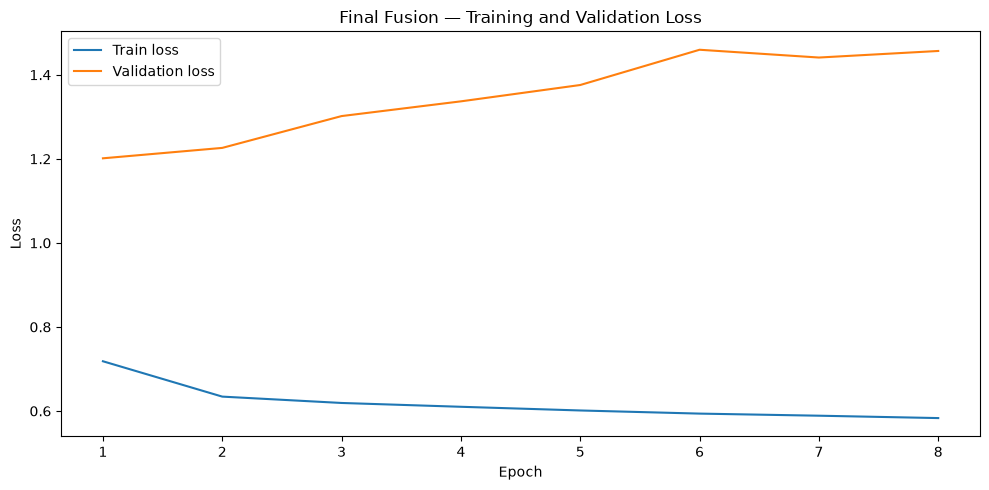

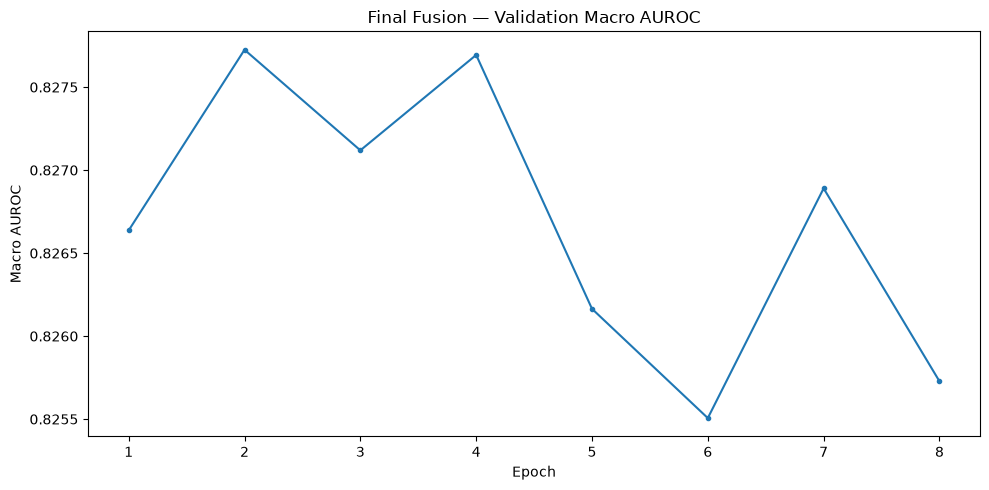

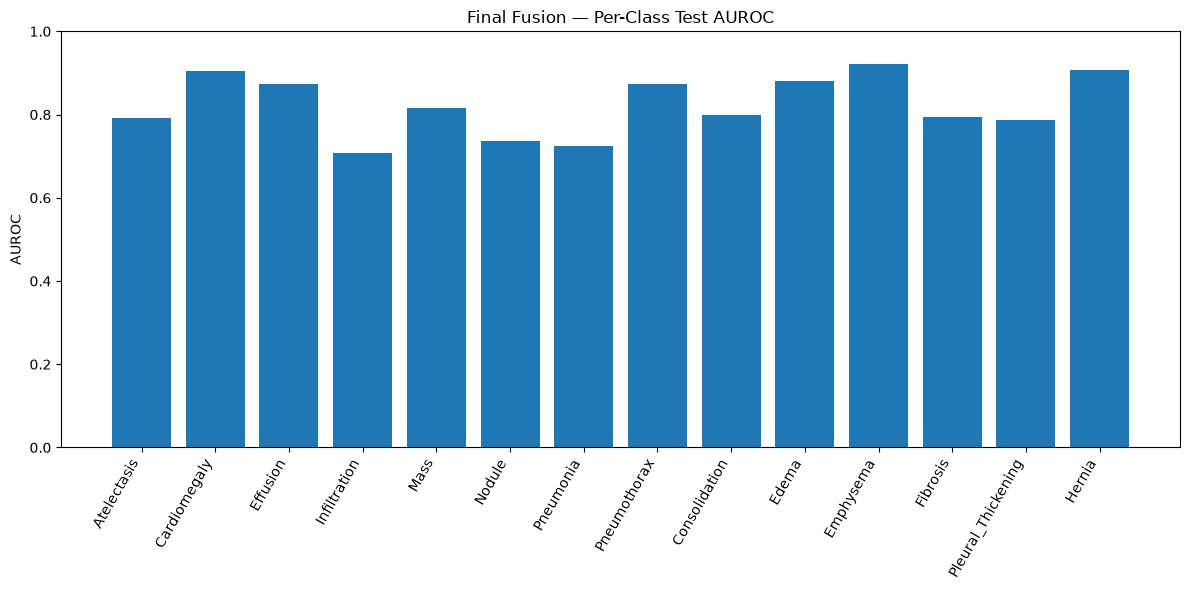

In [21]:
import matplotlib.pyplot as plt

# 1. Training curves
if len(history_df) > 0:
    fig = plt.figure(figsize=(10, 5))
    plt.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
    plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Final Fusion — Training and Validation Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=180)
    plt.show()

# 2. Validation AUROC
if len(history_df) > 0:
    fig = plt.figure(figsize=(10, 5))
    plt.plot(history_df["epoch"], history_df["val_auroc"], marker="o", markersize=3)
    plt.xlabel("Epoch")
    plt.ylabel("Macro AUROC")
    plt.title("Final Fusion — Validation Macro AUROC")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "validation_auroc_curve.png", dpi=180)
    plt.show()

# 3. Per-class AUROC bar chart
fig = plt.figure(figsize=(12, 6))
plt.bar(per_class_df["Disease"], per_class_df["AUROC"].fillna(0))
plt.xticks(rotation=60, ha="right")
plt.ylabel("AUROC")
plt.ylim(0, 1)
plt.title("Final Fusion — Per-Class Test AUROC")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_auroc.png", dpi=180)
plt.show()

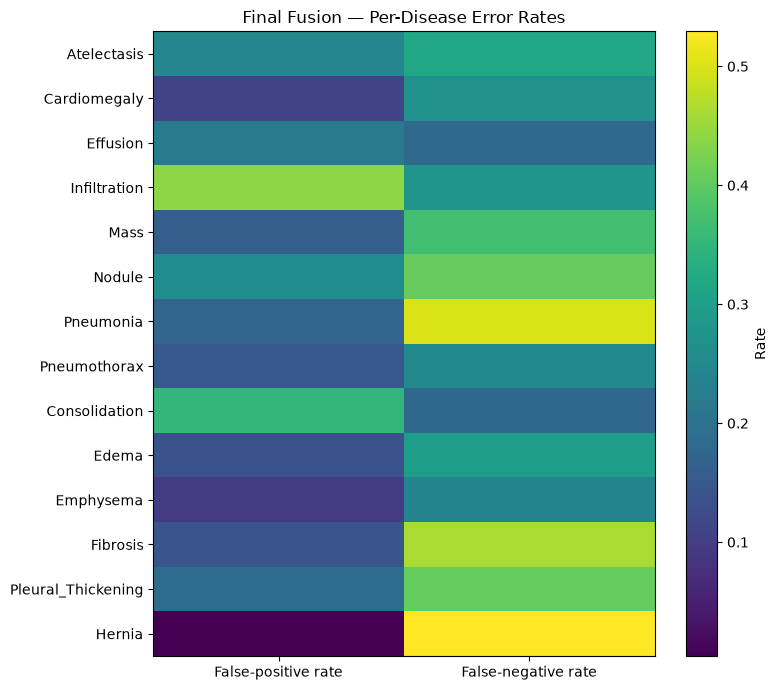

In [22]:
# 4. Confusion-style binary error heatmap across disease labels.
# For multilabel data this is a compact FN/FP rate visualization, not a
# mutually-exclusive multiclass confusion matrix.
from sklearn.metrics import confusion_matrix

error_rows = []
for i, disease in enumerate(DISEASES):
    cm = confusion_matrix(
        y_test[:, i].astype(int),
        (p_test[:, i] >= THRESHOLD).astype(int),
        labels=[0, 1]
    )
    tn, fp, fn, tp = cm.ravel()
    error_rows.append([
        fp / max(fp + tn, 1),
        fn / max(fn + tp, 1)
    ])

error_matrix = np.asarray(error_rows)

fig = plt.figure(figsize=(8, 7))
plt.imshow(error_matrix, aspect="auto")
plt.xticks([0, 1], ["False-positive rate", "False-negative rate"])
plt.yticks(range(NUM_CLASSES), DISEASES)
plt.colorbar(label="Rate")
plt.title("Final Fusion — Per-Disease Error Rates")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "error_rate_heatmap.png", dpi=180)
plt.show()

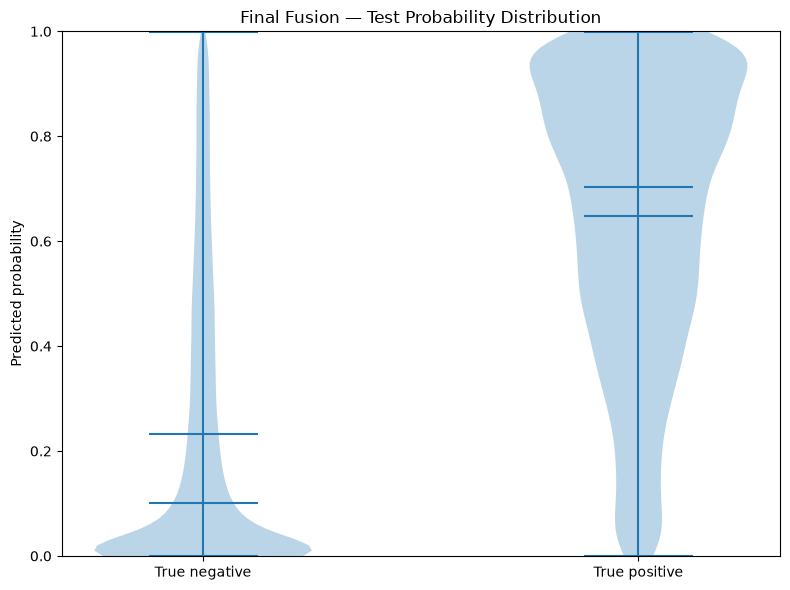

In [23]:
# 5. Violin chart: predicted probabilities for positive vs negative ground truth.
# Uses a compact sample when the test set is very large.
rng = np.random.default_rng(SEED)
sample_n = min(12000, len(y_test))
sample_idx = rng.choice(len(y_test), sample_n, replace=False)

positive_probs = []
negative_probs = []

for i in range(NUM_CLASSES):
    pos_mask = y_test[sample_idx, i] == 1
    neg_mask = y_test[sample_idx, i] == 0

    if pos_mask.any():
        positive_probs.extend(p_test[sample_idx[pos_mask], i].tolist())
    if neg_mask.any():
        negative_probs.extend(p_test[sample_idx[neg_mask], i].tolist())

fig = plt.figure(figsize=(8, 6))
plt.violinplot(
    [negative_probs, positive_probs],
    showmeans=True,
    showmedians=True
)
plt.xticks([1, 2], ["True negative", "True positive"])
plt.ylabel("Predicted probability")
plt.ylim(0, 1)
plt.title("Final Fusion — Test Probability Distribution")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "probability_violin.png", dpi=180)
plt.show()

,Hybrid_Dimension,Mean_DenseNet_Gate,Std_DenseNet_Gate
0,0,0.961931,0.021708
1,1,0.995755,0.004923
2,2,0.386884,0.086264
3,3,0.979875,0.019619
4,4,0.966496,0.022363
5,5,0.839240,0.089058
6,6,0.965994,0.024136
7,7,0.896747,0.033780
8,8,0.981775,0.011634
9,9,0.904428,0.035344


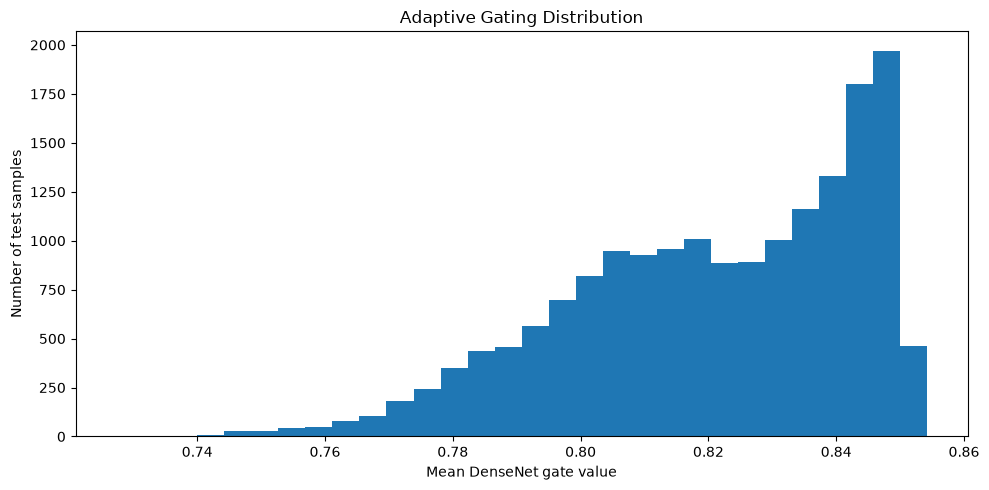

In [24]:
# 6. Gate statistics.
model.eval()
gate_batches = []

with torch.inference_mode():
    for xd, xm, _ in test_loader:
        xd = xd.to(DEVICE, non_blocking=True)
        xm = xm.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE,
            enabled=AMP_ENABLED
        ):
            _, _, gate = model(
                xd, xm, return_details=True
            )

        gate_batches.append(
            gate.float().cpu().numpy()
        )

gate_values = np.concatenate(gate_batches, axis=0)

gate_summary = pd.DataFrame({
    "Hybrid_Dimension": np.arange(PROJ_DIM),
    "Mean_DenseNet_Gate": gate_values.mean(axis=0),
    "Std_DenseNet_Gate": gate_values.std(axis=0),
})

display(gate_summary.head(20))

gate_summary.to_csv(
    OUTPUT_DIR / "gate_statistics.csv",
    index=False
)

fig = plt.figure(figsize=(10, 5))
plt.hist(gate_values.mean(axis=1), bins=30)
plt.xlabel("Mean DenseNet gate value")
plt.ylabel("Number of test samples")
plt.title("Adaptive Gating Distribution")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gate_distribution.png", dpi=180)
plt.show()

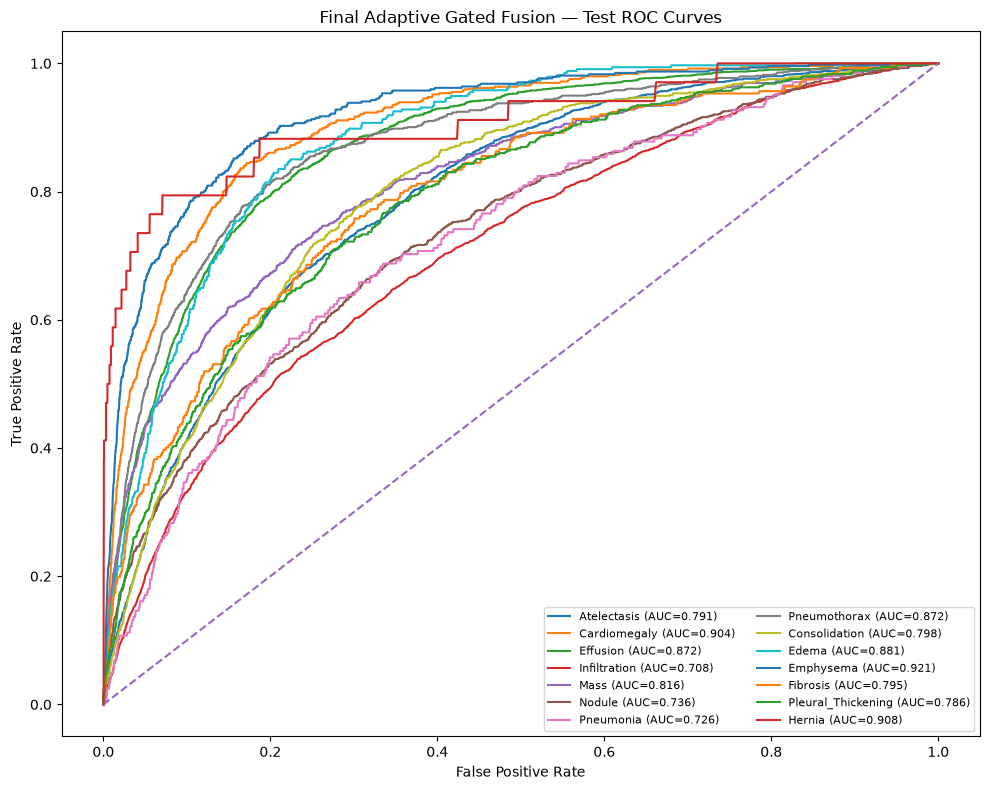

In [25]:
# 7. ROC curves
fig = plt.figure(figsize=(10, 8))

for i, disease in enumerate(DISEASES):
    if len(np.unique(y_test[:, i])) < 2:
        continue

    fpr, tpr, _ = roc_curve(
        y_test[:, i],
        p_test[:, i]
    )
    auc = roc_auc_score(
        y_test[:, i],
        p_test[:, i]
    )

    plt.plot(
        fpr, tpr,
        label=f"{disease} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Adaptive Gated Fusion — Test ROC Curves")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_roc_curves.png", dpi=180)
plt.show()

In [26]:
# Save image-level predictions for reproducibility.

test_ids = np.asarray(all_ids)[test_mask.detach().cpu().numpy()]

prediction_df = pd.DataFrame({
    "Image Index": test_ids
})

for i, disease in enumerate(DISEASES):
    prediction_df[f"True_{disease}"] = y_test[:, i].astype(np.int8)
    prediction_df[f"Prob_{disease}"] = p_test[:, i].astype(np.float32)
    prediction_df[f"Pred_{disease}"] = (
        p_test[:, i] >= THRESHOLD
    ).astype(np.int8)

prediction_df.to_csv(
    OUTPUT_DIR / "final_test_predictions.csv",
    index=False
)

print("Saved:", OUTPUT_DIR / "final_test_predictions.csv")
print("Test images:", len(prediction_df))

Saved: final_fusion_results/final_test_predictions.csv
Test images: 17448


## 10. Final prediction

The saved final model expects the paired 1024-D DenseNet and 512-D MedMamba features. For a raw uploaded X-ray, run the two frozen backbones first, then pass their features to this fusion head.


In [27]:

# Load best fusion checkpoint and provide a reusable raw-image prediction function.

checkpoint = torch.load(
    CHECKPOINT_FILE, map_location=DEVICE, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

def predict_raw_xray(image_path, top_k=5):
    """Run the two trained frozen backbones + final fusion head on one X-ray."""
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not read image: {image_path}")

    img = clahe_unsharp(img)
    img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    x = eval_transform(img).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        dense_feat = dense_model(x)
        mamba_feat = mamba_model(x)
        logits = model(dense_feat, mamba_feat)
        probs = torch.sigmoid(logits).cpu().numpy()[0]

    result = pd.DataFrame({
        "Disease": DISEASES,
        "Probability": probs
    }).sort_values("Probability", ascending=False)

    return result.head(top_k).reset_index(drop=True)

print("Final raw-X-ray prediction function is ready.")
print("Use: predict_raw_xray('/path/to/xray.png')")


Final raw-X-ray prediction function is ready.
Use: predict_raw_xray('/path/to/xray.png')


In [28]:
from pathlib import Path

# Find one NIH Chest X-ray image automatically
filename = all_ids[0]

matches = list(Path("/home").rglob(filename))

if not matches:
    matches = list(Path(".").rglob(filename))

if not matches:
    raise FileNotFoundError(f"Could not find {filename}")

xray_path = str(matches[0])

print("Testing image:", xray_path)

result = predict_raw_xray(xray_path)

display(result)

Testing image: /home/22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224/images-224/00000001_000.png


,Disease,Probability
0,Cardiomegaly,0.995422
1,Effusion,0.713376
2,Pneumonia,0.711362
3,Emphysema,0.583861
4,Fibrosis,0.529302


In [31]:
# ============================================================
# FINAL ONE-CELL CHEST X-RAY AI WEB APPLICATION (PRO UI v2)
# DenseNet121 + MedMamba + Adaptive Gated Fusion
# Backend logic = ORIGINAL (unchanged). Only HTML_FINAL is new.
# ============================================================

!pip install -q flask

import os
import io
import threading
import time

import numpy as np
import pandas as pd
import torch

from PIL import Image
from flask import Flask, request, jsonify, render_template_string

print("=" * 70)
print("CHEST X-RAY AI WEB APPLICATION")
print("=" * 70)

if "dense_model" not in globals():
    raise RuntimeError("dense_model is not available. Run the DenseNet checkpoint-loading cell first.")
if "mamba_model" not in globals():
    raise RuntimeError("mamba_model is not available. Run the MedMamba checkpoint-loading cell first.")
if "model" not in globals():
    raise RuntimeError("Fusion model 'model' is not available. Run the fusion model definition/loading cell first.")
if "DEVICE" not in globals():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("DEVICE :", DEVICE)
if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))

DISEASES = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration", "Mass",
    "Nodule", "Pneumonia", "Pneumothorax", "Consolidation", "Edema",
    "Emphysema", "Fibrosis", "Pleural_Thickening", "Hernia"
]

if "eval_transform" in globals():
    print("Using existing fusion eval_transform.")
    raw_transform = eval_transform
else:
    print("WARNING: eval_transform not found. Using standard ImageNet preprocessing.")
    from torchvision import transforms
    raw_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])


def predict_raw_xray(image_path):
    dense_model.eval()
    mamba_model.eval()
    model.eval()
    image = Image.open(image_path).convert("RGB")
    image_tensor = raw_transform(image).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        dense_features = dense_model(image_tensor)
        mamba_features = mamba_model(image_tensor)
        logits = model(dense_features, mamba_features)
        probabilities = torch.sigmoid(logits)[0]
        probabilities = probabilities.detach().float().cpu().numpy()
    result = pd.DataFrame({"Disease": DISEASES, "Probability": probabilities})
    return result.sort_values(by="Probability", ascending=False).reset_index(drop=True)


app_final = Flask("Chest_XRay_AI_Final")

HTML_FINAL = r"""
<!DOCTYPE html>
<html lang="en" data-theme="dark">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Chest X-Ray AI Analyzer</title>
<style>
:root{--bg:#060a13;--panel:rgba(255,255,255,.045);--line:rgba(255,255,255,.1);--text:#e8eef9;--muted:#8794ab;
--a:#38bdf8;--b:#6366f1;--ok:#22c55e;--warn:#f59e0b;--bad:#ef4444;--shadow:0 20px 60px rgba(0,0,0,.4);--inset:rgba(0,0,0,.28)}
[data-theme=light]{--bg:#f1f5fb;--panel:#fff;--line:#dfe6f1;--text:#12203a;--muted:#64748b;--shadow:0 12px 40px rgba(30,50,90,.1);--inset:#f3f6fb}
*{box-sizing:border-box;margin:0}
body{font-family:Inter,"Segoe UI",system-ui,Arial,sans-serif;color:var(--text);min-height:100vh;transition:background .3s;
background:radial-gradient(900px 500px at 8% -10%,rgba(99,102,241,.22),transparent 60%),radial-gradient(800px 500px at 100% 0,rgba(56,189,248,.16),transparent 60%),var(--bg)}
.header{display:flex;justify-content:space-between;align-items:center;padding:16px 5%;border-bottom:1px solid var(--line);position:sticky;top:0;z-index:9;backdrop-filter:blur(14px);background:color-mix(in srgb,var(--bg) 75%,transparent)}
.logo{display:flex;gap:12px;align-items:center}
.logo-i{width:42px;height:42px;border-radius:12px;display:grid;place-items:center;font-size:20px;background:linear-gradient(135deg,var(--b),var(--a));box-shadow:0 6px 24px rgba(56,189,248,.35)}
.logo-t{font-weight:800;font-size:18px}.logo-s{font-size:12px;color:var(--muted)}
.hr{display:flex;gap:12px;align-items:center}
.pill{display:flex;align-items:center;gap:8px;font-size:12px;font-weight:700;color:var(--ok);padding:7px 13px;border:1px solid rgba(34,197,94,.35);border-radius:99px;background:rgba(34,197,94,.08)}
.dot{width:8px;height:8px;border-radius:50%;background:var(--ok);animation:pl 1.8s infinite}
@keyframes pl{0%{box-shadow:0 0 0 0 rgba(34,197,94,.6)}100%{box-shadow:0 0 0 10px transparent}}
.clock{font-size:12px;color:var(--muted);font-variant-numeric:tabular-nums}
.ib{width:36px;height:36px;border-radius:10px;border:1px solid var(--line);background:var(--panel);color:var(--text);cursor:pointer;font-size:15px;transition:.2s}
.ib:hover{border-color:var(--a);transform:translateY(-1px)}
.wrap{width:92%;max-width:1320px;margin:32px auto 50px}
.hero h1{font-size:36px;letter-spacing:-.5px;background:linear-gradient(90deg,var(--text),var(--a));-webkit-background-clip:text;background-clip:text;color:transparent}
.hero p{color:var(--muted);margin:8px 0 18px;max-width:700px;line-height:1.55}
.chips{display:flex;gap:8px;flex-wrap:wrap;margin-bottom:24px}
.chip{font-size:12px;padding:6px 12px;border-radius:99px;border:1px solid var(--line);color:var(--muted);background:var(--panel)}
.grid{display:grid;grid-template-columns:1fr 1.25fr;gap:22px;align-items:start}
.card{background:var(--panel);border:1px solid var(--line);border-radius:20px;padding:22px;box-shadow:var(--shadow);backdrop-filter:blur(12px)}
.ct{font-size:16px;font-weight:800}.cs{color:var(--muted);font-size:13px;margin:4px 0 14px}
.view{position:relative;height:380px;border-radius:14px;border:2px dashed var(--line);background:#000;display:grid;place-items:center;overflow:hidden;cursor:pointer;transition:.25s}
.view:hover,.view.drag{border-color:var(--a)}
.view.has{border-style:solid;cursor:default}
.up{text-align:center;color:var(--muted);padding:20px}.up .e{font-size:50px;margin-bottom:8px}.up b{color:var(--text)}
#fi{display:none}
#pv{max-width:100%;max-height:100%;display:none;transition:transform .2s,filter .2s;transform-origin:center}
.scan{position:absolute;left:0;right:0;top:0;height:3px;display:none;background:linear-gradient(90deg,transparent,var(--a),transparent);box-shadow:0 0 24px 7px rgba(56,189,248,.6);animation:sc 1.7s ease-in-out infinite}
.view.busy .scan{display:block}
@keyframes sc{0%,100%{top:0}50%{top:calc(100% - 3px)}}
.tools{display:none;gap:8px;margin-top:12px;align-items:center;flex-wrap:wrap}
.tools label{font-size:11px;color:var(--muted);display:flex;align-items:center;gap:6px}
.tools input[type=range]{width:78px;accent-color:var(--a)}
.tb{padding:6px 10px;font-size:12px;border-radius:8px;border:1px solid var(--line);background:var(--panel);color:var(--text);cursor:pointer}
.tb:hover{border-color:var(--a)}
.finfo{display:none;justify-content:space-between;font-size:12px;color:var(--muted);margin-top:10px}
.btns{display:flex;gap:10px;margin-top:14px}
.btn{flex:1;padding:14px;border:none;border-radius:12px;font-weight:800;font-size:14px;cursor:pointer;color:#fff;letter-spacing:.5px;transition:.2s}
.bp{background:linear-gradient(135deg,var(--b),var(--a));box-shadow:0 8px 24px rgba(99,102,241,.4)}
.bp:hover:not(:disabled){transform:translateY(-2px)}
.bp:disabled{background:#334155;box-shadow:none;cursor:not-allowed;color:#94a3b8}
.bg{flex:0 0 100px;background:transparent;border:1px solid var(--line);color:var(--muted)}
.bg:hover{color:var(--text);border-color:var(--a)}
.steps{display:none;margin-top:14px;gap:6px}
.step{flex:1;text-align:center;font-size:10px;color:var(--muted);padding-top:9px;position:relative;font-weight:600}
.step::before{content:"";position:absolute;top:0;left:0;right:0;height:4px;border-radius:4px;background:var(--line);transition:.4s}
.step.on::before{background:var(--a);animation:bl 1s infinite}.step.done::before{background:var(--ok);animation:none}.step.done{color:var(--ok)}
@keyframes bl{50%{opacity:.4}}
.hist{margin-top:16px;display:none}
.hist h4{font-size:12px;color:var(--muted);margin-bottom:8px;font-weight:700;text-transform:uppercase;letter-spacing:1px}
.hl{display:flex;gap:8px;overflow-x:auto;padding-bottom:4px}
.hi{flex:0 0 96px;border:1px solid var(--line);border-radius:10px;overflow:hidden;cursor:pointer;background:var(--inset);transition:.2s}
.hi:hover,.hi.act{border-color:var(--a)}
.hi img{width:100%;height:56px;object-fit:cover;display:block}
.hi span{display:block;font-size:10px;padding:4px 6px;color:var(--muted);white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
.rh{display:flex;justify-content:space-between;align-items:center}
.badge{font-size:11px;font-weight:800;padding:6px 12px;border-radius:99px;color:var(--a);background:rgba(56,189,248,.1);border:1px solid rgba(56,189,248,.3)}
.top{display:flex;align-items:center;gap:20px;margin:16px 0;padding:18px;border-radius:16px;border:1px solid var(--line);background:linear-gradient(135deg,rgba(99,102,241,.16),rgba(56,189,248,.07))}
.ring{position:relative;width:108px;height:108px;flex:0 0 108px}.ring svg{transform:rotate(-90deg)}
.rbg{stroke:var(--line)}.rfg{stroke-linecap:round;transition:stroke-dashoffset 1.1s cubic-bezier(.2,.8,.2,1),stroke .4s}
.rt{position:absolute;inset:0;display:grid;place-items:center;font-size:20px;font-weight:800}
.tl{font-size:11px;text-transform:uppercase;letter-spacing:1px;color:var(--muted)}
.td{font-size:25px;font-weight:800;margin:3px 0 6px}
.risk{display:inline-block;font-size:11px;font-weight:800;padding:4px 10px;border-radius:99px}
.r-low{color:var(--ok);background:rgba(34,197,94,.13)}.r-mod{color:var(--warn);background:rgba(245,158,11,.13)}.r-high{color:var(--bad);background:rgba(239,68,68,.13)}.r-none{color:var(--muted);background:var(--line)}
.kpis{display:none;grid-template-columns:repeat(3,1fr);gap:10px;margin-bottom:16px}
.kpi{padding:12px;border-radius:12px;border:1px solid var(--line);background:var(--inset)}
.kpi b{display:block;font-size:11px;color:var(--muted);margin-bottom:3px;font-weight:600}.kpi span{font-size:19px;font-weight:800}
.ctl{display:none;gap:14px;align-items:center;flex-wrap:wrap;margin-bottom:14px;padding:12px;border:1px solid var(--line);border-radius:12px;background:var(--inset);font-size:12px;color:var(--muted)}
.ctl input[type=range]{accent-color:var(--a);width:130px;vertical-align:middle}
.seg{display:flex;border:1px solid var(--line);border-radius:8px;overflow:hidden}
.seg button{padding:6px 11px;border:none;background:transparent;color:var(--muted);cursor:pointer;font-size:12px}
.seg button.on{background:var(--a);color:#021;font-weight:700}
.sp{flex:1}
.row{margin-bottom:6px;padding:9px 10px;border-radius:10px;cursor:pointer;opacity:0;transform:translateY(8px);animation:in .4s forwards;border:1px solid transparent;transition:.2s}
.row:hover{background:var(--inset);border-color:var(--line)}
.row.flag{border-left:3px solid var(--bad)}
@keyframes in{to{opacity:1;transform:none}}
.rw{display:flex;justify-content:space-between;font-size:13px;margin-bottom:6px}
.rn{font-weight:700}.rv{font-weight:800;font-variant-numeric:tabular-nums}
.track{height:8px;background:var(--line);border-radius:9px;overflow:hidden;position:relative}
.bar{height:100%;width:0;border-radius:9px;transition:width 1s cubic-bezier(.2,.8,.2,1)}
.tm{position:absolute;top:-2px;bottom:-2px;width:2px;background:var(--text);opacity:.5}
.desc{max-height:0;overflow:hidden;font-size:12px;color:var(--muted);line-height:1.5;transition:max-height .3s,margin .3s}
.row.open .desc{max-height:70px;margin-top:8px}
.empty{text-align:center;color:var(--muted);padding:36px 10px;font-size:14px}
.err{padding:16px;border-radius:12px;background:rgba(239,68,68,.1);border:1px solid rgba(239,68,68,.35);color:#f87171}
.ex{display:none;gap:8px;margin-top:14px}.ex .tb{flex:1;padding:10px}
.mets{display:grid;grid-template-columns:repeat(3,1fr);gap:18px;margin-top:22px}
.met{padding:20px;text-align:center;border-radius:16px;border:1px solid var(--line);background:var(--panel)}
.mv{font-size:29px;font-weight:800;background:linear-gradient(90deg,var(--b),var(--a));-webkit-background-clip:text;background-clip:text;color:transparent}
.ml{font-size:12px;color:var(--muted);margin-top:4px}
.disc{margin-top:20px;padding:15px;border-radius:12px;font-size:12px;line-height:1.55;background:rgba(245,158,11,.09);border:1px solid rgba(245,158,11,.35);color:#d97706}
.toast{position:fixed;bottom:24px;left:50%;transform:translate(-50%,80px);background:var(--text);color:var(--bg);padding:11px 18px;border-radius:10px;font-size:13px;font-weight:600;transition:.35s;z-index:20}
.toast.show{transform:translate(-50%,0)}
@media(max-width:900px){.grid,.mets,.kpis{grid-template-columns:1fr}.top{flex-direction:column;text-align:center}.clock{display:none}}
@media print{.header,.view,.tools,.btns,.hist,.ex,.ctl,.steps{display:none!important}body{background:#fff;color:#000}}
</style>
</head>
<body>
<div class="header">
 <div class="logo"><div class="logo-i">🩺</div><div><div class="logo-t">Chest X-Ray AI</div><div class="logo-s">Adaptive Gated Fusion Analyzer</div></div></div>
 <div class="hr"><span class="clock" id="clock"></span><div class="pill"><span class="dot"></span>AI Model Ready</div><button class="ib" id="theme" title="Toggle theme">🌙</button></div>
</div>
<div class="wrap">
 <div class="hero"><h1>Chest X-Ray Analysis</h1>
  <p>AI-assisted multi-label screening for 14 thoracic conditions using DenseNet121 + MedMamba with adaptive feature-level fusion.</p>
  <div class="chips"><span class="chip">DenseNet121 · 1024-D</span><span class="chip">MedMamba · 512-D</span><span class="chip">Adaptive Gated Fusion</span><span class="chip">Multi-label · 14 Classes</span></div></div>
 <div class="grid">
  <div class="card">
   <div class="ct">X-Ray Viewer</div><div class="cs">Drag &amp; drop or click to upload. Adjust zoom, brightness and contrast to inspect.</div>
   <div class="view" id="view"><input type="file" id="fi" accept="image/png,image/jpeg,image/jpg">
    <div class="up" id="up"><div class="e">🩻</div><b>Drop X-ray here or click to browse</b><div style="font-size:12px;margin-top:6px">PNG / JPG / JPEG · Ctrl+V to paste</div></div>
    <img id="pv" alt="X-ray"><div class="scan"></div></div>
   <div class="tools" id="tools">
    <button class="tb" id="zi">＋</button><button class="tb" id="zo">－</button>
    <label>☀ <input type="range" id="br" min="50" max="170" value="100"></label>
    <label>◐ <input type="range" id="co" min="50" max="200" value="100"></label>
    <button class="tb" id="inv">Invert</button><button class="tb" id="vr">Reset view</button></div>
   <div class="finfo" id="finfo"><span id="fn"></span><span id="fs"></span></div>
   <div class="btns"><button class="btn bp" id="go" disabled>ANALYZE X-RAY</button><button class="btn bg" id="rs">Reset</button></div>
   <div class="steps" id="steps"><div class="step">Preprocess</div><div class="step">DenseNet121</div><div class="step">MedMamba</div><div class="step">Fusion</div></div>
   <div class="hist" id="hist"><h4>Session history</h4><div class="hl" id="hl"></div></div>
  </div>
  <div class="card">
   <div class="rh"><div class="ct">AI Analysis Results</div><div class="badge" id="badge">FUSION MODEL</div></div>
   <div class="top"><div class="ring"><svg width="108" height="108" viewBox="0 0 108 108"><circle class="rbg" cx="54" cy="54" r="45" fill="none" stroke-width="10"/><circle class="rfg" id="rfg" cx="54" cy="54" r="45" fill="none" stroke="#38bdf8" stroke-width="10" stroke-dasharray="283" stroke-dashoffset="283"/></svg><div class="rt" id="rt">—</div></div>
    <div><div class="tl">Highest Predicted Finding</div><div class="td" id="td">Awaiting image</div><span class="risk r-none" id="tr">Upload an X-ray to begin</span></div></div>
   <div class="kpis" id="kpis"></div>
   <div class="ctl" id="ctl">
    <span>Flag threshold <input type="range" id="th" min="5" max="95" value="50"> <b id="thv" style="color:var(--text)">50%</b></span>
    <span class="sp"></span>
    <div class="seg"><button id="s1" class="on">By risk</button><button id="s2">A–Z</button></div></div>
   <div id="res"><div class="empty">Disease probabilities will appear here.</div></div>
   <div class="ex" id="ex"><button class="tb" id="eJ">⬇ Export JSON</button><button class="tb" id="eP">🖨 Print report</button></div>
  </div>
 </div>
 <div class="mets"><div class="met"><div class="mv">82.23%</div><div class="ml">Test Macro AUROC</div></div><div class="met"><div class="mv">80.58%</div><div class="ml">Test Macro Accuracy</div></div><div class="met"><div class="mv">14</div><div class="ml">Disease Classes</div></div></div>
 <div class="disc"><b>Research / Decision Support:</b> This system provides model-generated probability estimates for research and demonstration purposes. Results should not be considered a medical diagnosis and must be reviewed by a qualified clinician.</div>
</div>
<div class="toast" id="toast"></div>
<script>
const $=i=>document.getElementById(i),C=283;
const INFO={Atelectasis:"Partial or complete collapse of lung tissue, reducing gas exchange.",Cardiomegaly:"Enlarged cardiac silhouette; may reflect heart failure or other cardiac disease.",Effusion:"Excess fluid in the pleural space, often blunting the costophrenic angle.",Infiltration:"Substance denser than air (fluid, cells, pus) within lung tissue.",Mass:"Focal opacity larger than 3 cm; warrants further work-up.",Nodule:"Small focal opacity of 3 cm or less; may be benign or malignant.",Pneumonia:"Lung infection causing inflammation and airspace opacities.",Pneumothorax:"Air in the pleural space causing partial or full lung collapse.",Consolidation:"Airspaces filled with fluid, pus or cells, producing dense opacity.",Edema:"Fluid accumulation in lung tissue, commonly cardiogenic.",Emphysema:"Over-inflation and destruction of alveoli, a form of COPD.",Fibrosis:"Scarring and thickening of lung tissue that reduces elasticity.",Pleural_Thickening:"Thickening of the pleural lining, sometimes from prior inflammation.",Hernia:"Protrusion of abdominal contents through the diaphragm."};
let S={z:1,inv:false,sort:"risk",cur:null,hist:[],timer:null,thumb:""};
const lvl=p=>p>=60?["High","r-high","#ef4444"]:p>=30?["Moderate","r-mod","#f59e0b"]:["Low","r-low","#22c55e"];
const esc=s=>String(s).replace(/[&<>"]/g,c=>({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;"}[c]));
const nm=s=>s.replace(/_/g," ");
function toast(m){const t=$("toast");t.textContent=m;t.classList.add("show");setTimeout(()=>t.classList.remove("show"),2200)}
function count(el,to,dec,suf){const t0=performance.now();(function f(n){const k=Math.min((n-t0)/900,1),e=1-Math.pow(1-k,3);el.textContent=(to*e).toFixed(dec)+suf;if(k<1)requestAnimationFrame(f)})(t0)}
setInterval(()=>$("clock").textContent=new Date().toLocaleString(),1000);$("clock").textContent=new Date().toLocaleString();
$("theme").onclick=()=>{const h=document.documentElement,d=h.dataset.theme==="dark";h.dataset.theme=d?"light":"dark";$("theme").textContent=d?"☀️":"🌙"};
function filt(){$("pv").style.filter=`brightness(${$("br").value}%) contrast(${$("co").value}%)${S.inv?" invert(1)":""}`;$("pv").style.transform=`scale(${S.z})`}
["br","co"].forEach(i=>$(i).oninput=filt);
$("zi").onclick=()=>{S.z=Math.min(S.z+.25,4);filt()};$("zo").onclick=()=>{S.z=Math.max(S.z-.25,1);filt()};
$("inv").onclick=()=>{S.inv=!S.inv;filt()};
$("vr").onclick=()=>{S.z=1;S.inv=false;$("br").value=100;$("co").value=100;filt()};
$("view").addEventListener("wheel",e=>{if(!$("view").classList.contains("has"))return;e.preventDefault();S.z=Math.min(4,Math.max(1,S.z+(e.deltaY<0?.15:-.15)));filt()},{passive:false});
function setFile(f){if(!f||!f.type.startsWith("image/"))return toast("Please choose an image file");
 const dt=new DataTransfer();dt.items.add(f);$("fi").files=dt.files;
 const r=new FileReader();r.onload=e=>{S.thumb=e.target.result;$("pv").src=S.thumb;$("pv").style.display="block";$("up").style.display="none";$("view").classList.add("has")};r.readAsDataURL(f);
 $("fn").textContent=f.name;$("fs").textContent=(f.size/1024).toFixed(1)+" KB";$("finfo").style.display="flex";$("tools").style.display="flex";$("go").disabled=false;$("vr").click()}
$("view").onclick=()=>{if(!$("view").classList.contains("has"))$("fi").click()};
$("fi").onchange=function(){setFile(this.files[0])};
["dragenter","dragover"].forEach(v=>$("view").addEventListener(v,e=>{e.preventDefault();$("view").classList.add("drag")}));
["dragleave","drop"].forEach(v=>$("view").addEventListener(v,e=>{e.preventDefault();$("view").classList.remove("drag")}));
$("view").addEventListener("drop",e=>setFile(e.dataTransfer.files[0]));
document.addEventListener("paste",e=>{const it=[...e.clipboardData.items].find(i=>i.type.startsWith("image/"));if(it)setFile(it.getAsFile())});
$("rs").onclick=()=>{$("fi").value="";$("pv").style.display="none";$("up").style.display="block";$("view").classList.remove("has");
 ["finfo","tools","kpis","ctl","ex","steps"].forEach(i=>$(i).style.display="none");$("go").disabled=true;S.cur=null;
 $("td").textContent="Awaiting image";$("tr").className="risk r-none";$("tr").textContent="Upload an X-ray to begin";$("rt").textContent="—";$("rfg").style.strokeDashoffset=C;
 $("res").innerHTML='<div class="empty">Disease probabilities will appear here.</div>'};
function steps(run){const s=[...document.querySelectorAll(".step")];$("steps").style.display="flex";s.forEach(x=>x.className="step");
 if(!run){s.forEach(x=>x.className="step done");return}let i=0;s[0].classList.add("on");
 S.timer=setInterval(()=>{if(i<3){s[i].className="step done";i++;s[i].classList.add("on")}},550)}
function render(d,anim){S.cur=d;const th=+$("th").value;
 const [l,c,col]=lvl(d.top_probability);
 $("td").textContent=nm(d.top_disease);$("tr").className="risk "+c;$("tr").textContent=l+" probability";
 count($("rt"),d.top_probability,1,"%");$("rfg").style.stroke=col;$("rfg").style.strokeDashoffset=C-C*Math.min(d.top_probability,100)/100;
 const fl=d.results.filter(r=>r.probability>=th).length,avg=d.results.reduce((a,r)=>a+r.probability,0)/d.results.length;
 $("kpis").innerHTML=`<div class="kpi"><b>Flagged ≥ ${th}%</b><span style="color:${fl?"var(--bad)":"var(--ok)"}">${fl} / 14</span></div><div class="kpi"><b>Mean probability</b><span>${avg.toFixed(1)}%</span></div><div class="kpi"><b>Inference time</b><span>${d.ms?(d.ms/1000).toFixed(2)+" s":"—"}</span></div>`;
 ["kpis","ctl","ex"].forEach(i=>$(i).style.display=i==="ex"?"flex":(i==="kpis"?"grid":"flex"));
 const rows=[...d.results].sort((a,b)=>S.sort==="risk"?b.probability-a.probability:a.disease.localeCompare(b.disease));
 $("res").innerHTML="";
 rows.forEach((r,i)=>{const cc=lvl(r.probability)[2],el=document.createElement("div");
  el.className="row"+(r.probability>=th?" flag":"");el.style.animationDelay=(anim?i*45:0)+"ms";
  el.innerHTML=`<div class="rw"><span class="rn">${esc(nm(r.disease))}</span><span class="rv" style="color:${cc}">0.00%</span></div><div class="track"><div class="bar" style="background:${cc}"></div><div class="tm" style="left:${th}%"></div></div><div class="desc">${esc(INFO[r.disease]||"")}</div>`;
  el.onclick=()=>el.classList.toggle("open");$("res").appendChild(el);
  setTimeout(()=>{el.querySelector(".bar").style.width=Math.min(r.probability,100)+"%";count(el.querySelector(".rv"),r.probability,2,"%")},60+(anim?i*45:0))})}
$("th").oninput=()=>{$("thv").textContent=$("th").value+"%";if(S.cur)render(S.cur,false)};
$("s1").onclick=()=>{S.sort="risk";$("s1").className="on";$("s2").className="";if(S.cur)render(S.cur,true)};
$("s2").onclick=()=>{S.sort="az";$("s2").className="on";$("s1").className="";if(S.cur)render(S.cur,true)};
function drawHist(){$("hist").style.display="block";$("hl").innerHTML=S.hist.map((h,i)=>`<div class="hi${h===S.cur?" act":""}" data-i="${i}"><img src="${h.thumb}"><span>${esc(nm(h.top_disease))} ${h.top_probability.toFixed(0)}%</span></div>`).join("");
 document.querySelectorAll(".hi").forEach(e=>e.onclick=()=>{const h=S.hist[+e.dataset.i];$("pv").src=h.thumb;render(h,true);drawHist()})}
$("go").onclick=async()=>{const f=$("fi").files[0];if(!f)return;
 $("go").disabled=true;$("view").classList.add("busy");steps(true);const t0=performance.now();
 const fd=new FormData();fd.append("image",f);
 try{const res=await fetch("./predict",{method:"POST",body:fd}),d=await res.json();
  if(!res.ok)throw new Error(d.error||"Prediction failed");
  d.ms=performance.now()-t0;d.thumb=S.thumb;d.file=f.name;d.time=new Date().toISOString();
  clearInterval(S.timer);steps(false);S.hist.unshift(d);render(d,true);drawHist();toast("Analysis complete")}
 catch(e){clearInterval(S.timer);$("steps").style.display="none";$("res").innerHTML=`<div class="err"><b>Prediction failed:</b><br><br>${esc(e.message)}</div>`}
 finally{$("go").disabled=false;$("view").classList.remove("busy")}};
$("eJ").onclick=()=>{if(!S.cur)return;const o={file:S.cur.file,time:S.cur.time,top_finding:S.cur.top_disease,results:S.cur.results},a=document.createElement("a");
 a.href=URL.createObjectURL(new Blob([JSON.stringify(o,null,2)],{type:"application/json"}));a.download="xray_report.json";a.click();toast("Report exported")};
$("eP").onclick=()=>window.print();
</script>
</body>
</html>
"""


@app_final.route("/")
def home_final():
    return render_template_string(HTML_FINAL)


@app_final.route("/predict", methods=["POST"])
def predict_final():
    try:
        if "image" not in request.files:
            return jsonify({"error": "No image uploaded."}), 400

        uploaded_file = request.files["image"]
        image_bytes = uploaded_file.read()

        if not image_bytes:
            return jsonify({"error": "Uploaded file is empty."}), 400

        image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

        dense_model.eval()
        mamba_model.eval()
        model.eval()

        image_tensor = raw_transform(image).unsqueeze(0).to(DEVICE)

        with torch.inference_mode():
            dense_features = dense_model(image_tensor)
            mamba_features = mamba_model(image_tensor)
            logits = model(dense_features, mamba_features)
            probabilities = torch.sigmoid(logits)[0]
            probabilities = probabilities.detach().float().cpu().numpy()

        df = pd.DataFrame({"Disease": DISEASES, "Probability": probabilities})
        df = df.sort_values(by="Probability", ascending=False).reset_index(drop=True)

        results = []
        for _, row in df.iterrows():
            results.append({
                "disease": str(row["Disease"]),
                "probability": float(row["Probability"]) * 100
            })

        return jsonify({
            "top_disease": results[0]["disease"],
            "top_probability": results[0]["probability"],
            "results": results
        })

    except Exception as e:
        return jsonify({"error": str(e)}), 500


FINAL_PORT = 7862


def run_final_flask():
    app_final.run(host="0.0.0.0", port=FINAL_PORT, debug=False,
                  use_reloader=False, threaded=True)


final_thread = threading.Thread(target=run_final_flask, daemon=True)
final_thread.start()
time.sleep(2)

print()
print("=" * 70)
print("CHEST X-RAY AI WEB APPLICATION READY")
print("=" * 70)
print()
print("DenseNet121        : READY")
print("MedMamba           : READY")
print("Adaptive Fusion    : READY")
print("Raw Image Inference: READY")
print("14 Disease Output  : READY")
print("Flask Web UI       : READY")
print()
print("OPEN THIS URL:")
print()
print("https://hpc.kongu.edu/user/22csr090/proxy/7862/")
print()
print("=" * 70)

CHEST X-RAY AI WEB APPLICATION
DEVICE : cuda
GPU    : NVIDIA H200 NVL
Using existing fusion eval_transform.
 * Serving Flask app 'Chest_XRay_AI_Final'
 * Debug mode: off


Address already in use
Port 7862 is in use by another program. Either identify and stop that program, or start the server with a different port.



CHEST X-RAY AI WEB APPLICATION READY

DenseNet121        : READY
MedMamba           : READY
Adaptive Fusion    : READY
Raw Image Inference: READY
14 Disease Output  : READY
Flask Web UI       : READY

OPEN THIS URL:

https://hpc.kongu.edu/user/22csr090/proxy/7862/



127.0.0.1 - - [06/Oct/2026 11:48:42] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [06/Oct/2026 11:48:58] "POST /predict HTTP/1.1" 200 -


In [32]:
# ============================================================
# FINAL FUSION - DISEASE-WISE METRICS INCLUDING ACCURACY
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use the arrays already produced by the final test evaluation
# y_test = ground truth
# p_test = predicted probabilities

per_class_rows = []

for i, disease in enumerate(DISEASES):

    y_i = y_test[:, i]

    p_i = p_test[:, i]

    pred_i = (
        p_i >= 0.50
    ).astype(np.int32)


    auc = (
        roc_auc_score(
            y_i,
            p_i
        )
        if len(np.unique(y_i)) >= 2
        else np.nan
    )


    accuracy = accuracy_score(
        y_i,
        pred_i
    )


    precision = precision_score(
        y_i,
        pred_i,
        zero_division=0
    )


    recall = recall_score(
        y_i,
        pred_i,
        zero_division=0
    )


    f1 = f1_score(
        y_i,
        pred_i,
        zero_division=0
    )


    per_class_rows.append({

        "Disease": disease,

        "AUROC": auc,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1": f1

    })


fusion_per_class_df = pd.DataFrame(
    per_class_rows
)


print()
print("=" * 90)
print("FUSION MODEL - DISEASE-WISE TEST METRICS")
print("=" * 90)

display(
    fusion_per_class_df.style.format({
        "AUROC": "{:.2%}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)


# Save it
fusion_per_class_df.to_csv(
    OUTPUT_DIR / "fusion_per_class_test_metrics.csv",
    index=False
)


print()
print(
    "Saved:",
    OUTPUT_DIR / "fusion_per_class_test_metrics.csv"
)


FUSION MODEL - DISEASE-WISE TEST METRICS


,Disease,AUROC,Accuracy,Precision,Recall,F1
0,Atelectasis,79.12%,74.60%,23.60%,68.11%,35.06%
1,Cardiomegaly,90.44%,88.34%,15.97%,72.93%,26.20%
2,Effusion,87.23%,78.39%,32.85%,81.49%,46.82%
3,Infiltration,70.80%,58.90%,26.13%,72.27%,38.38%
4,Mass,81.57%,82.82%,14.85%,62.86%,24.02%
5,Nodule,73.56%,73.13%,11.91%,59.30%,19.83%
6,Pneumonia,72.57%,82.03%,3.25%,49.76%,6.11%
7,Pneumothorax,87.23%,84.63%,20.10%,74.37%,31.65%
8,Consolidation,79.78%,65.66%,9.75%,81.97%,17.42%
9,Edema,88.08%,86.01%,9.12%,70.36%,16.15%



Saved: final_fusion_results/fusion_per_class_test_metrics.csv


In [33]:
# ============================================================
# VALIDATION-BASED PER-DISEASE THRESHOLD OPTIMIZATION
#
# Goal:
#   Improve accuracy while NOT reducing recall
#   compared with the current 0.50 threshold.
#
# IMPORTANT:
#   Thresholds are selected ONLY from validation data.
#   The test set remains untouched until final evaluation.
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    precision_score,
    f1_score
)

print("=" * 90)
print("VALIDATION-BASED THRESHOLD OPTIMIZATION")
print("=" * 90)


# ============================================================
# 1. GET VALIDATION PREDICTIONS
# ============================================================

val_metrics_current, y_val, p_val = evaluate(
    val_loader
)


# ============================================================
# 2. CURRENT TEST BASELINE
# ============================================================

test_pred_current = (
    p_test >= 0.50
).astype(np.int32)


old_test_accuracy_per_class = []

old_test_recall_per_class = []


for i in range(NUM_CLASSES):

    old_test_accuracy_per_class.append(
        accuracy_score(
            y_test[:, i],
            test_pred_current[:, i]
        )
    )


    old_test_recall_per_class.append(
        recall_score(
            y_test[:, i],
            test_pred_current[:, i],
            zero_division=0
        )
    )


# ============================================================
# 3. FIND BEST THRESHOLD FOR EACH DISEASE
#
# Constraint:
# New validation recall >= current validation recall
#
# Among those thresholds:
# choose the one with highest validation accuracy.
# ============================================================

optimized_thresholds = []

threshold_rows = []


threshold_grid = np.arange(
    0.05,
    0.96,
    0.01
)


for i, disease in enumerate(DISEASES):

    y = y_val[:, i]

    p = p_val[:, i]


    # Current 0.50 baseline
    baseline_pred = (
        p >= 0.50
    ).astype(np.int32)


    baseline_recall = recall_score(
        y,
        baseline_pred,
        zero_division=0
    )


    baseline_accuracy = accuracy_score(
        y,
        baseline_pred
    )


    candidates = []


    for threshold in threshold_grid:

        pred = (
            p >= threshold
        ).astype(np.int32)


        acc = accuracy_score(
            y,
            pred
        )


        rec = recall_score(
            y,
            pred,
            zero_division=0
        )


        # Only accept threshold if recall
        # does not decrease
        if rec >= baseline_recall:

            candidates.append({

                "threshold": threshold,

                "accuracy": acc,

                "recall": rec

            })


    if len(candidates) == 0:

        best_threshold = 0.50

        best_accuracy = baseline_accuracy

        best_recall = baseline_recall

    else:

        best = max(
            candidates,
            key=lambda x: (
                x["accuracy"],
                x["recall"]
            )
        )

        best_threshold = best["threshold"]

        best_accuracy = best["accuracy"]

        best_recall = best["recall"]


    optimized_thresholds.append(
        best_threshold
    )


    threshold_rows.append({

        "Disease": disease,

        "Old_Threshold": 0.50,

        "New_Threshold": best_threshold,

        "Validation_Accuracy": best_accuracy,

        "Validation_Recall": best_recall

    })


threshold_df = pd.DataFrame(
    threshold_rows
)


# ============================================================
# 4. DISPLAY THRESHOLDS
# ============================================================

print()
print(
    "Optimized disease-specific thresholds:"
)

display(
    threshold_df.style.format({

        "Old_Threshold": "{:.2f}",

        "New_Threshold": "{:.2f}",

        "Validation_Accuracy": "{:.2%}",

        "Validation_Recall": "{:.2%}"

    })
)


# Save
threshold_df.to_csv(
    OUTPUT_DIR / "optimized_disease_thresholds.csv",
    index=False
)


print()
print(
    "Saved:",
    OUTPUT_DIR / "optimized_disease_thresholds.csv"
)

VALIDATION-BASED THRESHOLD OPTIMIZATION

Optimized disease-specific thresholds:


,Disease,Old_Threshold,New_Threshold,Validation_Accuracy,Validation_Recall
0,Atelectasis,0.50,0.49,75.07%,69.58%
1,Cardiomegaly,0.50,0.50,87.91%,73.26%
2,Effusion,0.50,0.50,79.43%,83.34%
3,Infiltration,0.50,0.49,57.33%,71.57%
4,Mass,0.50,0.50,83.40%,63.75%
5,Nodule,0.50,0.50,74.59%,63.91%
6,Pneumonia,0.50,0.50,82.23%,38.68%
7,Pneumothorax,0.50,0.50,87.18%,65.61%
8,Consolidation,0.50,0.50,66.60%,83.08%
9,Edema,0.50,0.50,86.31%,76.11%



Saved: final_fusion_results/optimized_disease_thresholds.csv


In [34]:
# ============================================================
# FINAL TEST EVALUATION WITH VALIDATION-OPTIMIZED THRESHOLDS
# ============================================================

optimized_thresholds = np.array(
    optimized_thresholds
)

# Apply the optimized thresholds to the untouched TEST set
test_pred_optimized = np.zeros_like(
    p_test,
    dtype=np.int32
)

for i in range(NUM_CLASSES):

    test_pred_optimized[:, i] = (
        p_test[:, i] >= optimized_thresholds[i]
    ).astype(np.int32)


# ============================================================
# DISEASE-WISE TEST RESULTS
# ============================================================

optimized_rows = []

for i, disease in enumerate(DISEASES):

    y_i = y_test[:, i]

    p_i = p_test[:, i]

    pred_i = test_pred_optimized[:, i]


    auc = roc_auc_score(
        y_i,
        p_i
    )

    accuracy = accuracy_score(
        y_i,
        pred_i
    )

    precision = precision_score(
        y_i,
        pred_i,
        zero_division=0
    )

    recall = recall_score(
        y_i,
        pred_i,
        zero_division=0
    )

    f1 = f1_score(
        y_i,
        pred_i,
        zero_division=0
    )


    optimized_rows.append({

        "Disease": disease,

        "Threshold": optimized_thresholds[i],

        "AUROC": auc,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1": f1
    })


# ============================================================
# CREATE FINAL TABLE
# ============================================================

optimized_df = pd.DataFrame(
    optimized_rows
)


# ============================================================
# MACRO RESULTS
# ============================================================

optimized_macro_auroc = (
    optimized_df["AUROC"].mean()
)

optimized_macro_accuracy = (
    optimized_df["Accuracy"].mean()
)

optimized_macro_precision = (
    optimized_df["Precision"].mean()
)

optimized_macro_recall = (
    optimized_df["Recall"].mean()
)

optimized_macro_f1 = (
    optimized_df["F1"].mean()
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print()
print("=" * 90)
print("FINAL TEST RESULTS - OPTIMIZED THRESHOLDS")
print("=" * 90)

print(
    f"Macro AUROC    : {optimized_macro_auroc:.4f} "
    f"({optimized_macro_auroc:.2%})"
)

print(
    f"Macro Accuracy : {optimized_macro_accuracy:.4f} "
    f"({optimized_macro_accuracy:.2%})"
)

print(
    f"Macro Precision: {optimized_macro_precision:.4f} "
    f"({optimized_macro_precision:.2%})"
)

print(
    f"Macro Recall   : {optimized_macro_recall:.4f} "
    f"({optimized_macro_recall:.2%})"
)

print(
    f"Macro F1       : {optimized_macro_f1:.4f} "
    f"({optimized_macro_f1:.2%})"
)


# ============================================================
# DISEASE-WISE TABLE
# ============================================================

print()
print("=" * 90)
print("DISEASE-WISE FINAL TEST RESULTS")
print("=" * 90)

display(
    optimized_df.style.format({

        "Threshold": "{:.2f}",

        "AUROC": "{:.2%}",

        "Accuracy": "{:.2%}",

        "Precision": "{:.2%}",

        "Recall": "{:.2%}",

        "F1": "{:.2%}"

    })
)


# ============================================================
# SAVE FINAL RESULT
# ============================================================

optimized_df.to_csv(
    OUTPUT_DIR /
    "fusion_final_optimized_per_class_metrics.csv",
    index=False
)

print()
print(
    "Saved:",
    OUTPUT_DIR /
    "fusion_final_optimized_per_class_metrics.csv"
)

Task was destroyed but it is pending!
task: <Task pending name='Task-465' coro=<_async_in_context.<locals>.run_in_context() done, defined at /opt/tljh/user/lib/python3.12/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-466' coro=<Kernel.shell_main() running at /opt/tljh/user/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /opt/tljh/user/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:563]>
Task was destroyed but it is pending!
task: <Task pending name='Task-466' coro=<Kernel.shell_main() running at /opt/tljh/user/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>



FINAL TEST RESULTS - OPTIMIZED THRESHOLDS
Macro AUROC    : 0.8224 (82.24%)
Macro Accuracy : 0.8053 (80.53%)
Macro Precision: 0.1579 (15.79%)
Macro Recall   : 0.6621 (66.21%)
Macro F1       : 0.2462 (24.62%)

DISEASE-WISE FINAL TEST RESULTS


,Disease,Threshold,AUROC,Accuracy,Precision,Recall,F1
0,Atelectasis,0.49,79.12%,73.88%,23.20%,69.02%,34.72%
1,Cardiomegaly,0.50,90.44%,88.35%,15.97%,72.93%,26.21%
2,Effusion,0.50,87.23%,78.41%,32.86%,81.44%,46.83%
3,Infiltration,0.49,70.80%,57.19%,25.62%,74.41%,38.11%
4,Mass,0.50,81.57%,82.83%,14.86%,62.86%,24.04%
5,Nodule,0.50,73.56%,73.17%,11.93%,59.30%,19.86%
6,Pneumonia,0.50,72.57%,82.04%,3.26%,49.76%,6.11%
7,Pneumothorax,0.50,87.23%,84.63%,20.11%,74.37%,31.66%
8,Consolidation,0.50,79.78%,65.68%,9.75%,81.97%,17.43%
9,Edema,0.50,88.08%,86.02%,9.12%,70.36%,16.15%



Saved: final_fusion_results/fusion_final_optimized_per_class_metrics.csv


In [35]:
# ============================================================
# FINAL CONTROLLED FUSION OPTIMIZATION
#
# Uses ALREADY EXTRACTED DenseNet + MedMamba FEATURES
# No feature extraction
# No backbone retraining
#
# Goal:
#   Improve validation Macro Accuracy while maintaining
#   strong AUROC and Recall.
# ============================================================

import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


print("=" * 80)
print("FINAL CONTROLLED FUSION OPTIMIZATION")
print("=" * 80)


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required = [
    "X_D",
    "X_M",
    "Y",
    "train_mask",
    "val_mask",
    "test_mask",
    "DEVICE",
    "DISEASES"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:

    raise RuntimeError(
        "Missing variables: "
        + str(missing)
        + "\nRun the feature-loading cells first."
    )


print("Feature tensors found.")
print("DenseNet features :", X_D.shape)
print("MedMamba features :", X_M.shape)
print("Labels            :", Y.shape)


# ============================================================
# 2. DATA LOADERS
# ============================================================

optimization_batch_size = 4096

train_dataset_opt = TensorDataset(
    X_D[train_mask],
    X_M[train_mask],
    Y[train_mask]
)

val_dataset_opt = TensorDataset(
    X_D[val_mask],
    X_M[val_mask],
    Y[val_mask]
)


train_loader_opt = DataLoader(
    train_dataset_opt,
    batch_size=optimization_batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_opt = DataLoader(
    val_dataset_opt,
    batch_size=optimization_batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ============================================================
# 3. BASE CLASS WEIGHTS
# ============================================================

train_labels_opt = Y[
    train_mask
].float()


positive_count_opt = (
    train_labels_opt.sum(dim=0)
)

negative_count_opt = (
    train_labels_opt.shape[0]
    - positive_count_opt
)


base_pos_weight = (
    negative_count_opt
    /
    positive_count_opt.clamp_min(1.0)
)


print()
print("Original positive weights:")
print(
    base_pos_weight.cpu().numpy()
)


# ============================================================
# 4. FUSION MODEL FACTORY
# ============================================================

def create_fusion_model():

    return AdaptiveGatedFusion().to(
        DEVICE
    )


# ============================================================
# 5. VALIDATION FUNCTION
# ============================================================

def evaluate_optimization_model(
    candidate_model,
    loader
):

    candidate_model.eval()

    all_y = []

    all_p = []


    with torch.inference_mode():

        for xd, xm, y in loader:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = candidate_model(
                    xd,
                    xm
                )


            probabilities = torch.sigmoid(
                logits
            )


            all_y.append(
                y.cpu().numpy()
            )

            all_p.append(
                probabilities
                .float()
                .cpu()
                .numpy()
            )


    y_true = np.concatenate(
        all_y
    )

    y_prob = np.concatenate(
        all_p
    )


    y_pred = (
        y_prob >= 0.50
    ).astype(
        np.int32
    )


    class_auc = []

    class_acc = []

    class_precision = []

    class_recall = []

    class_f1 = []


    for i in range(
        len(DISEASES)
    ):

        yt = y_true[:, i]

        yp = y_prob[:, i]

        pred = y_pred[:, i]


        if len(
            np.unique(yt)
        ) >= 2:

            class_auc.append(
                roc_auc_score(
                    yt,
                    yp
                )
            )


        class_acc.append(
            accuracy_score(
                yt,
                pred
            )
        )


        class_precision.append(
            precision_score(
                yt,
                pred,
                zero_division=0
            )
        )


        class_recall.append(
            recall_score(
                yt,
                pred,
                zero_division=0
            )
        )


        class_f1.append(
            f1_score(
                yt,
                pred,
                zero_division=0
            )
        )


    return {

        "auroc": float(
            np.mean(class_auc)
        ),

        "accuracy": float(
            np.mean(class_acc)
        ),

        "precision": float(
            np.mean(class_precision)
        ),

        "recall": float(
            np.mean(class_recall)
        ),

        "f1": float(
            np.mean(class_f1)
        ),

        "y_true": y_true,

        "y_prob": y_prob

    }


# ============================================================
# 6. EXPERIMENT SETTINGS
# ============================================================

experiments = {

    "Current_1.00": 1.00,

    "Balanced_0.75": 0.75,

    "Balanced_0.50": 0.50,

    "Balanced_0.35": 0.35

}


# ============================================================
# 7. TRAIN EACH CANDIDATE
# ============================================================

candidate_results = []

candidate_models = {}


for experiment_name, weight_power in experiments.items():

    print()
    print("=" * 80)
    print(
        "EXPERIMENT:",
        experiment_name
    )
    print("=" * 80)


    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    candidate_model = create_fusion_model()


    # --------------------------------------------------------
    # Adjust class weights
    # --------------------------------------------------------

    experiment_pos_weight = (
        base_pos_weight
        .pow(weight_power)
        .to(DEVICE)
    )


    criterion_opt = (
        nn.BCEWithLogitsLoss(
            pos_weight=experiment_pos_weight
        )
    )


    optimizer_opt = torch.optim.AdamW(

        candidate_model.parameters(),

        lr=2e-4,

        weight_decay=1e-4

    )


    scheduler_opt = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer_opt,
            T_max=12
        )
    )


    scaler_opt = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )


    best_auc = -1.0

    best_state = None

    best_epoch_local = 0


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    for epoch in range(
        1,
        13
    ):

        candidate_model.train()


        for xd, xm, y in train_loader_opt:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            y = y.to(
                DEVICE,
                non_blocking=True
            )


            optimizer_opt.zero_grad(
                set_to_none=True
            )


            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = candidate_model(
                    xd,
                    xm
                )

                loss = criterion_opt(
                    logits,
                    y
                )


            scaler_opt.scale(
                loss
            ).backward()


            scaler_opt.unscale_(
                optimizer_opt
            )


            torch.nn.utils.clip_grad_norm_(
                candidate_model.parameters(),
                max_norm=1.0
            )


            scaler_opt.step(
                optimizer_opt
            )

            scaler_opt.update()


        scheduler_opt.step()


        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_result = evaluate_optimization_model(
            candidate_model,
            val_loader_opt
        )


        print(
            f"Epoch {epoch:02d} | "
            f"AUC={val_result['auroc']:.4f} | "
            f"ACC={val_result['accuracy']:.4f} | "
            f"REC={val_result['recall']:.4f}"
        )


        # ----------------------------------------------------
        # Select best epoch by balanced objective
        #
        # Accuracy is important,
        # but don't sacrifice AUROC/recall.
        # ----------------------------------------------------

        objective = (

            0.50 *
            val_result["accuracy"]

            +

            0.30 *
            val_result["auroc"]

            +

            0.20 *
            val_result["recall"]

        )


        if (
            best_state is None
            or
            objective >
            best_auc
        ):

            best_auc = objective

            best_state = copy.deepcopy(
                candidate_model.state_dict()
            )

            best_epoch_local = epoch


    # --------------------------------------------------------
    # Restore best epoch
    # --------------------------------------------------------

    candidate_model.load_state_dict(
        best_state
    )


    final_val = evaluate_optimization_model(
        candidate_model,
        val_loader_opt
    )


    candidate_results.append({

        "Experiment":
            experiment_name,

        "Weight_Power":
            weight_power,

        "Val_AUROC":
            final_val["auroc"],

        "Val_Accuracy":
            final_val["accuracy"],

        "Val_Precision":
            final_val["precision"],

        "Val_Recall":
            final_val["recall"],

        "Val_F1":
            final_val["f1"],

        "Best_Epoch":
            best_epoch_local

    })


    candidate_models[
        experiment_name
    ] = candidate_model


# ============================================================
# 8. COMPARE EXPERIMENTS
# ============================================================

experiment_df = pd.DataFrame(
    candidate_results
)


print()
print("=" * 80)
print("VALIDATION EXPERIMENT COMPARISON")
print("=" * 80)


display(
    experiment_df.style.format({

        "Val_AUROC":
            "{:.2%}",

        "Val_Accuracy":
            "{:.2%}",

        "Val_Precision":
            "{:.2%}",

        "Val_Recall":
            "{:.2%}",

        "Val_F1":
            "{:.2%}"

    })
)


# ============================================================
# 9. SELECT BEST MODEL
#
# Require:
#   AUROC >= 80%
#   Recall >= 60%
#
# Then maximize accuracy.
# ============================================================

eligible = experiment_df[
    (experiment_df["Val_AUROC"] >= 0.80)
    &
    (experiment_df["Val_Recall"] >= 0.60)
]


if len(eligible) == 0:

    print()
    print(
        "No candidate met both safety constraints."
    )

    best_experiment_name = (
        experiment_df
        .sort_values(
            [
                "Val_AUROC",
                "Val_Recall",
                "Val_Accuracy"
            ],
            ascending=False
        )
        .iloc[0]["Experiment"]
    )

else:

    best_experiment_name = (
        eligible
        .sort_values(
            [
                "Val_Accuracy",
                "Val_AUROC",
                "Val_Recall"
            ],
            ascending=False
        )
        .iloc[0]["Experiment"]
    )


best_candidate_model = candidate_models[
    best_experiment_name
]


print()
print("=" * 80)
print("SELECTED FUSION MODEL")
print("=" * 80)

print(
    "Selected:",
    best_experiment_name
)


# ============================================================
# 10. SAVE CANDIDATE COMPARISON
# ============================================================

experiment_df.to_csv(
    OUTPUT_DIR /
    "fusion_optimization_comparison.csv",
    index=False
)


print()
print(
    "Saved:",
    OUTPUT_DIR /
    "fusion_optimization_comparison.csv"
)


# ============================================================
# 11. FINAL TEST — ONLY AFTER MODEL SELECTION
# ============================================================

test_dataset_opt = TensorDataset(
    X_D[test_mask],
    X_M[test_mask],
    Y[test_mask]
)


test_loader_opt = DataLoader(
    test_dataset_opt,
    batch_size=optimization_batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


final_test_result = (
    evaluate_optimization_model(
        best_candidate_model,
        test_loader_opt
    )
)


# ============================================================
# 12. FINAL TEST SUMMARY
# ============================================================

print()
print("=" * 80)
print("FINAL OPTIMIZED FUSION TEST RESULT")
print("=" * 80)

print(
    f"Macro AUROC    : "
    f"{final_test_result['auroc']:.4f} "
    f"({final_test_result['auroc']:.2%})"
)

print(
    f"Macro Accuracy : "
    f"{final_test_result['accuracy']:.4f} "
    f"({final_test_result['accuracy']:.2%})"
)

print(
    f"Macro Precision: "
    f"{final_test_result['precision']:.4f} "
    f"({final_test_result['precision']:.2%})"
)

print(
    f"Macro Recall   : "
    f"{final_test_result['recall']:.4f} "
    f"({final_test_result['recall']:.2%})"
)

print(
    f"Macro F1       : "
    f"{final_test_result['f1']:.4f} "
    f"({final_test_result['f1']:.2%})"
)


# ============================================================
# 13. DISEASE-WISE FINAL TEST METRICS
# ============================================================

y_test_final = (
    final_test_result["y_true"]
)

p_test_final = (
    final_test_result["y_prob"]
)


pred_test_final = (
    p_test_final >= 0.50
).astype(
    np.int32
)


final_rows = []


for i, disease in enumerate(
    DISEASES
):

    yt = y_test_final[:, i]

    yp = p_test_final[:, i]

    pred = pred_test_final[:, i]


    final_rows.append({

        "Disease":
            disease,

        "AUROC":
            roc_auc_score(
                yt,
                yp
            ),

        "Accuracy":
            accuracy_score(
                yt,
                pred
            ),

        "Precision":
            precision_score(
                yt,
                pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                yt,
                pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                yt,
                pred,
                zero_division=0
            )

    })


final_per_class_df = pd.DataFrame(
    final_rows
)


print()
print("=" * 80)
print("FINAL DISEASE-WISE TEST RESULTS")
print("=" * 80)


display(
    final_per_class_df.style.format({

        "AUROC":
            "{:.2%}",

        "Accuracy":
            "{:.2%}",

        "Precision":
            "{:.2%}",

        "Recall":
            "{:.2%}",

        "F1":
            "{:.2%}"

    })
)


# ============================================================
# 14. SAVE FINAL RESULTS
# ============================================================

final_per_class_df.to_csv(
    OUTPUT_DIR /
    "FINAL_FUSION_DISEASE_WISE_METRICS.csv",
    index=False
)


print()
print(
    "Saved:"
)

print(
    OUTPUT_DIR /
    "FINAL_FUSION_DISEASE_WISE_METRICS.csv"
)


# ============================================================
# 15. SAVE SELECTED MODEL
# ============================================================

final_optimized_checkpoint = {

    "model_state_dict":
        best_candidate_model.state_dict(),

    "experiment":
        best_experiment_name,

    "test_auroc":
        final_test_result["auroc"],

    "test_accuracy":
        final_test_result["accuracy"],

    "test_precision":
        final_test_result["precision"],

    "test_recall":
        final_test_result["recall"],

    "test_f1":
        final_test_result["f1"]

}


torch.save(
    final_optimized_checkpoint,
    OUTPUT_DIR /
    "BEST_FINAL_ADAPTIVE_GATED_FUSION.pt"
)


print(
    "Saved:",
    OUTPUT_DIR /
    "BEST_FINAL_ADAPTIVE_GATED_FUSION.pt"
)


print()
print("=" * 80)
print("OPTIMIZATION COMPLETE")
print("=" * 80)

FINAL CONTROLLED FUSION OPTIMIZATION
Feature tensors found.
DenseNet features : torch.Size([112120, 1024])
MedMamba features : torch.Size([112120, 512])
Labels            : torch.Size([112120, 14])

Original positive weights:
[  8.610519   40.613346    7.3288455   4.673045   17.534088   16.755028
  82.938034   19.85085    23.33891    47.2        46.158463   66.96367
  32.0248    496.25317  ]

EXPERIMENT: Current_1.00
Epoch 01 | AUC=0.8131 | ACC=0.7686 | REC=0.7062
Epoch 02 | AUC=0.8254 | ACC=0.8134 | REC=0.6650
Epoch 03 | AUC=0.8269 | ACC=0.8307 | REC=0.6372
Epoch 04 | AUC=0.8277 | ACC=0.8248 | REC=0.6485
Epoch 05 | AUC=0.8279 | ACC=0.8284 | REC=0.6448
Epoch 06 | AUC=0.8278 | ACC=0.8289 | REC=0.6434
Epoch 07 | AUC=0.8278 | ACC=0.8302 | REC=0.6423
Epoch 08 | AUC=0.8278 | ACC=0.8300 | REC=0.6430
Epoch 09 | AUC=0.8279 | ACC=0.8322 | REC=0.6391
Epoch 10 | AUC=0.8277 | ACC=0.8338 | REC=0.6375
Epoch 11 | AUC=0.8277 | ACC=0.8322 | REC=0.6391
Epoch 12 | AUC=0.8277 | ACC=0.8324 | REC=0.6393

EX

,Experiment,Weight_Power,Val_AUROC,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Best_Epoch
0,Current_1.00,1.000000,82.77%,83.38%,16.84%,63.75%,25.72%,10
1,Balanced_0.75,0.750000,82.68%,89.30%,21.72%,50.86%,29.34%,5
2,Balanced_0.50,0.500000,82.73%,92.74%,27.95%,36.40%,30.82%,7
3,Balanced_0.35,0.350000,82.62%,94.01%,32.13%,27.09%,28.38%,12



SELECTED FUSION MODEL
Selected: Current_1.00

Saved: final_fusion_results/fusion_optimization_comparison.csv

FINAL OPTIMIZED FUSION TEST RESULT
Macro AUROC    : 0.8223 (82.23%)
Macro Accuracy : 0.8262 (82.62%)
Macro Precision: 0.1638 (16.38%)
Macro Recall   : 0.6411 (64.11%)
Macro F1       : 0.2525 (25.25%)

FINAL DISEASE-WISE TEST RESULTS


,Disease,AUROC,Accuracy,Precision,Recall,F1
0,Atelectasis,79.09%,71.37%,21.83%,71.47%,33.44%
1,Cardiomegaly,90.44%,89.23%,16.98%,71.92%,27.48%
2,Effusion,87.17%,79.81%,34.28%,79.48%,47.90%
3,Infiltration,70.58%,69.30%,30.91%,59.30%,40.63%
4,Mass,81.52%,83.58%,15.22%,61.27%,24.39%
5,Nodule,73.77%,76.17%,12.97%,56.95%,21.13%
6,Pneumonia,73.08%,86.19%,3.77%,43.90%,6.95%
7,Pneumothorax,87.21%,84.18%,19.66%,74.73%,31.13%
8,Consolidation,79.77%,73.20%,11.28%,73.80%,19.57%
9,Edema,88.10%,86.39%,9.39%,70.66%,16.58%



Saved:
final_fusion_results/FINAL_FUSION_DISEASE_WISE_METRICS.csv
Saved: final_fusion_results/BEST_FINAL_ADAPTIVE_GATED_FUSION.pt

OPTIMIZATION COMPLETE


In [ ]:
# ============================================================
# FINAL FINE-GRAINED FUSION OPTIMIZATION
# Goal:
#   Increase accuracy while preserving AUROC and recall
#
# Uses existing extracted DenseNet + MedMamba features.
# Does NOT repeat feature extraction.
# ============================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 80)
print("FINE-GRAINED FUSION OPTIMIZATION")
print("=" * 80)


# ============================================================
# 1. DATA LOADERS
# ============================================================

BATCH_SIZE_FINE = 4096

train_dataset_fine = TensorDataset(
    X_D[train_mask],
    X_M[train_mask],
    Y[train_mask]
)

val_dataset_fine = TensorDataset(
    X_D[val_mask],
    X_M[val_mask],
    Y[val_mask]
)

train_loader_fine = DataLoader(
    train_dataset_fine,
    batch_size=BATCH_SIZE_FINE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_fine = DataLoader(
    val_dataset_fine,
    batch_size=BATCH_SIZE_FINE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ============================================================
# 2. ORIGINAL CLASS WEIGHTS
# ============================================================

train_labels_fine = Y[train_mask].float()

positive_count_fine = train_labels_fine.sum(dim=0)

negative_count_fine = (
    train_labels_fine.shape[0]
    - positive_count_fine
)

base_weight_fine = (
    negative_count_fine
    /
    positive_count_fine.clamp_min(1.0)
)

print()
print("Original class weights:")
print(base_weight_fine.cpu().numpy())


# ============================================================
# 3. EVALUATION
# ============================================================

def evaluate_fine(model, loader):

    model.eval()

    all_y = []
    all_p = []

    with torch.inference_mode():

        for xd, xm, y in loader:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model(xd, xm)

            probabilities = torch.sigmoid(logits)

            all_y.append(
                y.cpu().numpy()
            )

            all_p.append(
                probabilities.float()
                .cpu()
                .numpy()
            )

    y_true = np.concatenate(all_y)

    y_prob = np.concatenate(all_p)

    y_pred = (
        y_prob >= 0.50
    ).astype(np.int32)

    aucs = []
    accuracies = []
    precisions = []
    recalls = []
    f1s = []

    for i in range(len(DISEASES)):

        yt = y_true[:, i]
        yp = y_prob[:, i]
        pred = y_pred[:, i]

        if len(np.unique(yt)) >= 2:

            aucs.append(
                roc_auc_score(yt, yp)
            )

        accuracies.append(
            accuracy_score(yt, pred)
        )

        precisions.append(
            precision_score(
                yt,
                pred,
                zero_division=0
            )
        )

        recalls.append(
            recall_score(
                yt,
                pred,
                zero_division=0
            )

        )

        f1s.append(
            f1_score(
                yt,
                pred,
                zero_division=0
            )
        )

    return {
        "auroc": np.mean(aucs),
        "accuracy": np.mean(accuracies),
        "precision": np.mean(precisions),
        "recall": np.mean(recalls),
        "f1": np.mean(f1s),
        "y_true": y_true,
        "y_prob": y_prob
    }


# ============================================================
# 4. FINE-GRAINED WEIGHT VALUES
# ============================================================

weight_experiments = [
    0.95,
    0.90,
    0.85,
    0.80
]


results_fine = []

models_fine = {}


# ============================================================
# 5. TRAIN
# ============================================================

for weight_power in weight_experiments:

    print()
    print("=" * 80)
    print(
        f"WEIGHT POWER = {weight_power:.2f}"
    )
    print("=" * 80)

    model_fine = AdaptiveGatedFusion().to(
        DEVICE
    )

    class_weight = (
        base_weight_fine
        .pow(weight_power)
        .to(DEVICE)
    )

    criterion_fine = (
        nn.BCEWithLogitsLoss(
            pos_weight=class_weight
        )
    )

    optimizer_fine = torch.optim.AdamW(
        model_fine.parameters(),
        lr=2e-4,
        weight_decay=1e-4
    )

    scheduler_fine = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer_fine,
            T_max=15
        )
    )

    scaler_fine = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    best_objective = -999

    best_state = None

    best_epoch = 0


    # --------------------------------------------------------
    # 15 epochs
    # --------------------------------------------------------

    for epoch in range(1, 16):

        model_fine.train()

        for xd, xm, y in train_loader_fine:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            y = y.to(
                DEVICE,
                non_blocking=True
            )

            optimizer_fine.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model_fine(
                    xd,
                    xm
                )

                loss = criterion_fine(
                    logits,
                    y
                )

            scaler_fine.scale(
                loss
            ).backward()

            scaler_fine.unscale_(
                optimizer_fine
            )

            torch.nn.utils.clip_grad_norm_(
                model_fine.parameters(),
                1.0
            )

            scaler_fine.step(
                optimizer_fine
            )

            scaler_fine.update()


        scheduler_fine.step()


        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val = evaluate_fine(
            model_fine,
            val_loader_fine
        )


        print(
            f"Epoch {epoch:02d} | "
            f"AUC={val['auroc']:.4f} | "
            f"ACC={val['accuracy']:.4f} | "
            f"REC={val['recall']:.4f}"
        )


        # ----------------------------------------------------
        # Selection objective
        #
        # Accuracy gets highest importance.
        # AUROC and recall protect disease detection.
        # ----------------------------------------------------

        objective = (

            0.50 * val["accuracy"]

            +

            0.30 * val["auroc"]

            +

            0.20 * val["recall"]

        )


        if objective > best_objective:

            best_objective = objective

            best_state = copy.deepcopy(
                model_fine.state_dict()
            )

            best_epoch = epoch


    # --------------------------------------------------------
    # Restore best epoch
    # --------------------------------------------------------

    model_fine.load_state_dict(
        best_state
    )


    final_val = evaluate_fine(
        model_fine,
        val_loader_fine
    )


    results_fine.append({

        "Weight_Power":
            weight_power,

        "Val_AUROC":
            final_val["auroc"],

        "Val_Accuracy":
            final_val["accuracy"],

        "Val_Precision":
            final_val["precision"],

        "Val_Recall":
            final_val["recall"],

        "Val_F1":
            final_val["f1"],

        "Best_Epoch":
            best_epoch

    })


    models_fine[
        weight_power
    ] = model_fine


# ============================================================
# 6. VALIDATION COMPARISON
# ============================================================

fine_df = pd.DataFrame(
    results_fine
)

print()
print("=" * 80)
print("FINE-GRAINED VALIDATION COMPARISON")
print("=" * 80)

display(
    fine_df.style.format({

        "Val_AUROC":
            "{:.2%}",

        "Val_Accuracy":
            "{:.2%}",

        "Val_Precision":
            "{:.2%}",

        "Val_Recall":
            "{:.2%}",

        "Val_F1":
            "{:.2%}"

    })
)


# ============================================================
# 7. SELECT MODEL
#
# Required:
#   AUROC >= 82%
#   Recall >= 60%
#
# Then maximize Accuracy.
# ============================================================

eligible_fine = fine_df[
    (fine_df["Val_AUROC"] >= 0.82)
    &
    (fine_df["Val_Recall"] >= 0.60)
]


if len(eligible_fine) == 0:

    print()
    print(
        "No new candidate passed the safety constraints."
    )

    print(
        "Keeping the previously selected fusion model."
    )

    selected_weight = None

else:

    selected_weight = (
        eligible_fine
        .sort_values(
            [
                "Val_Accuracy",
                "Val_AUROC",
                "Val_Recall"
            ],
            ascending=False
        )
        .iloc[0]["Weight_Power"]
    )

    print()
    print(
        "BEST NEW WEIGHT POWER:",
        selected_weight
    )


# ============================================================
# 8. TEST ONLY IF A NEW MODEL PASSED
# ============================================================

if selected_weight is not None:

    selected_model = models_fine[
        selected_weight
    ]

    test_dataset_fine = TensorDataset(
        X_D[test_mask],
        X_M[test_mask],
        Y[test_mask]
    )

    test_loader_fine = DataLoader(
        test_dataset_fine,
        batch_size=BATCH_SIZE_FINE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    final_test_fine = evaluate_fine(
        selected_model,
        test_loader_fine
    )


    print()
    print("=" * 80)
    print("FINAL TEST RESULT — FINE-GRAINED OPTIMIZATION")
    print("=" * 80)

    print(
        f"Macro AUROC    : "
        f"{final_test_fine['auroc']:.2%}"
    )

    print(
        f"Macro Accuracy : "
        f"{final_test_fine['accuracy']:.2%}"
    )

    print(
        f"Macro Precision: "
        f"{final_test_fine['precision']:.2%}"
    )

    print(
        f"Macro Recall   : "
        f"{final_test_fine['recall']:.2%}"
    )

    print(
        f"Macro F1       : "
        f"{final_test_fine['f1']:.2%}"
    )


    # --------------------------------------------------------
    # Save candidate
    # --------------------------------------------------------

    torch.save(
        {
            "model_state_dict":
                selected_model.state_dict(),

            "weight_power":
                selected_weight,

            "test_auroc":
                final_test_fine["auroc"],

            "test_accuracy":
                final_test_fine["accuracy"],

            "test_recall":
                final_test_fine["recall"],

            "test_f1":
                final_test_fine["f1"]

        },
        OUTPUT_DIR /
        "FINE_OPTIMIZED_FUSION.pt"
    )


    fine_df.to_csv(
        OUTPUT_DIR /
        "fine_grained_optimization.csv",
        index=False
    )


    print()
    print(
        "Saved optimized model:"
    )

    print(
        OUTPUT_DIR /
        "FINE_OPTIMIZED_FUSION.pt"
    )

else:

    print()
    print(
        "No new model selected."
    )

print()
print("=" * 80)
print("DONE")
print("=" * 80)

In [36]:
# ============================================================
# FINAL FINE-GRAINED FUSION OPTIMIZATION
# Goal:
#   Increase accuracy while preserving AUROC and recall
#
# Uses existing extracted DenseNet + MedMamba features.
# Does NOT repeat feature extraction.
# ============================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 80)
print("FINE-GRAINED FUSION OPTIMIZATION")
print("=" * 80)


# ============================================================
# 1. DATA LOADERS
# ============================================================

BATCH_SIZE_FINE = 4096

train_dataset_fine = TensorDataset(
    X_D[train_mask],
    X_M[train_mask],
    Y[train_mask]
)

val_dataset_fine = TensorDataset(
    X_D[val_mask],
    X_M[val_mask],
    Y[val_mask]
)

train_loader_fine = DataLoader(
    train_dataset_fine,
    batch_size=BATCH_SIZE_FINE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_fine = DataLoader(
    val_dataset_fine,
    batch_size=BATCH_SIZE_FINE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ============================================================
# 2. ORIGINAL CLASS WEIGHTS
# ============================================================

train_labels_fine = Y[train_mask].float()

positive_count_fine = train_labels_fine.sum(dim=0)

negative_count_fine = (
    train_labels_fine.shape[0]
    - positive_count_fine
)

base_weight_fine = (
    negative_count_fine
    /
    positive_count_fine.clamp_min(1.0)
)

print()
print("Original class weights:")
print(base_weight_fine.cpu().numpy())


# ============================================================
# 3. EVALUATION
# ============================================================

def evaluate_fine(model, loader):

    model.eval()

    all_y = []
    all_p = []

    with torch.inference_mode():

        for xd, xm, y in loader:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model(xd, xm)

            probabilities = torch.sigmoid(logits)

            all_y.append(
                y.cpu().numpy()
            )

            all_p.append(
                probabilities.float()
                .cpu()
                .numpy()
            )

    y_true = np.concatenate(all_y)

    y_prob = np.concatenate(all_p)

    y_pred = (
        y_prob >= 0.50
    ).astype(np.int32)

    aucs = []
    accuracies = []
    precisions = []
    recalls = []
    f1s = []

    for i in range(len(DISEASES)):

        yt = y_true[:, i]
        yp = y_prob[:, i]
        pred = y_pred[:, i]

        if len(np.unique(yt)) >= 2:

            aucs.append(
                roc_auc_score(yt, yp)
            )

        accuracies.append(
            accuracy_score(yt, pred)
        )

        precisions.append(
            precision_score(
                yt,
                pred,
                zero_division=0
            )
        )

        recalls.append(
            recall_score(
                yt,
                pred,
                zero_division=0
            )

        )

        f1s.append(
            f1_score(
                yt,
                pred,
                zero_division=0
            )
        )

    return {
        "auroc": np.mean(aucs),
        "accuracy": np.mean(accuracies),
        "precision": np.mean(precisions),
        "recall": np.mean(recalls),
        "f1": np.mean(f1s),
        "y_true": y_true,
        "y_prob": y_prob
    }


# ============================================================
# 4. FINE-GRAINED WEIGHT VALUES
# ============================================================

weight_experiments = [
    0.95,
    0.90,
    0.85,
    0.80
]


results_fine = []

models_fine = {}


# ============================================================
# 5. TRAIN
# ============================================================

for weight_power in weight_experiments:

    print()
    print("=" * 80)
    print(
        f"WEIGHT POWER = {weight_power:.2f}"
    )
    print("=" * 80)

    model_fine = AdaptiveGatedFusion().to(
        DEVICE
    )

    class_weight = (
        base_weight_fine
        .pow(weight_power)
        .to(DEVICE)
    )

    criterion_fine = (
        nn.BCEWithLogitsLoss(
            pos_weight=class_weight
        )
    )

    optimizer_fine = torch.optim.AdamW(
        model_fine.parameters(),
        lr=2e-4,
        weight_decay=1e-4
    )

    scheduler_fine = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer_fine,
            T_max=15
        )
    )

    scaler_fine = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    best_objective = -999

    best_state = None

    best_epoch = 0


    # --------------------------------------------------------
    # 15 epochs
    # --------------------------------------------------------

    for epoch in range(1, 16):

        model_fine.train()

        for xd, xm, y in train_loader_fine:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            y = y.to(
                DEVICE,
                non_blocking=True
            )

            optimizer_fine.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model_fine(
                    xd,
                    xm
                )

                loss = criterion_fine(
                    logits,
                    y
                )

            scaler_fine.scale(
                loss
            ).backward()

            scaler_fine.unscale_(
                optimizer_fine
            )

            torch.nn.utils.clip_grad_norm_(
                model_fine.parameters(),
                1.0
            )

            scaler_fine.step(
                optimizer_fine
            )

            scaler_fine.update()


        scheduler_fine.step()


        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val = evaluate_fine(
            model_fine,
            val_loader_fine
        )


        print(
            f"Epoch {epoch:02d} | "
            f"AUC={val['auroc']:.4f} | "
            f"ACC={val['accuracy']:.4f} | "
            f"REC={val['recall']:.4f}"
        )


        # ----------------------------------------------------
        # Selection objective
        #
        # Accuracy gets highest importance.
        # AUROC and recall protect disease detection.
        # ----------------------------------------------------

        objective = (

            0.50 * val["accuracy"]

            +

            0.30 * val["auroc"]

            +

            0.20 * val["recall"]

        )


        if objective > best_objective:

            best_objective = objective

            best_state = copy.deepcopy(
                model_fine.state_dict()
            )

            best_epoch = epoch


    # --------------------------------------------------------
    # Restore best epoch
    # --------------------------------------------------------

    model_fine.load_state_dict(
        best_state
    )


    final_val = evaluate_fine(
        model_fine,
        val_loader_fine
    )


    results_fine.append({

        "Weight_Power":
            weight_power,

        "Val_AUROC":
            final_val["auroc"],

        "Val_Accuracy":
            final_val["accuracy"],

        "Val_Precision":
            final_val["precision"],

        "Val_Recall":
            final_val["recall"],

        "Val_F1":
            final_val["f1"],

        "Best_Epoch":
            best_epoch

    })


    models_fine[
        weight_power
    ] = model_fine


# ============================================================
# 6. VALIDATION COMPARISON
# ============================================================

fine_df = pd.DataFrame(
    results_fine
)

print()
print("=" * 80)
print("FINE-GRAINED VALIDATION COMPARISON")
print("=" * 80)

display(
    fine_df.style.format({

        "Val_AUROC":
            "{:.2%}",

        "Val_Accuracy":
            "{:.2%}",

        "Val_Precision":
            "{:.2%}",

        "Val_Recall":
            "{:.2%}",

        "Val_F1":
            "{:.2%}"

    })
)


# ============================================================
# 7. SELECT MODEL
#
# Required:
#   AUROC >= 82%
#   Recall >= 60%
#
# Then maximize Accuracy.
# ============================================================

eligible_fine = fine_df[
    (fine_df["Val_AUROC"] >= 0.82)
    &
    (fine_df["Val_Recall"] >= 0.60)
]


if len(eligible_fine) == 0:

    print()
    print(
        "No new candidate passed the safety constraints."
    )

    print(
        "Keeping the previously selected fusion model."
    )

    selected_weight = None

else:

    selected_weight = (
        eligible_fine
        .sort_values(
            [
                "Val_Accuracy",
                "Val_AUROC",
                "Val_Recall"
            ],
            ascending=False
        )
        .iloc[0]["Weight_Power"]
    )

    print()
    print(
        "BEST NEW WEIGHT POWER:",
        selected_weight
    )


# ============================================================
# 8. TEST ONLY IF A NEW MODEL PASSED
# ============================================================

if selected_weight is not None:

    selected_model = models_fine[
        selected_weight
    ]

    test_dataset_fine = TensorDataset(
        X_D[test_mask],
        X_M[test_mask],
        Y[test_mask]
    )

    test_loader_fine = DataLoader(
        test_dataset_fine,
        batch_size=BATCH_SIZE_FINE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    final_test_fine = evaluate_fine(
        selected_model,
        test_loader_fine
    )


    print()
    print("=" * 80)
    print("FINAL TEST RESULT — FINE-GRAINED OPTIMIZATION")
    print("=" * 80)

    print(
        f"Macro AUROC    : "
        f"{final_test_fine['auroc']:.2%}"
    )

    print(
        f"Macro Accuracy : "
        f"{final_test_fine['accuracy']:.2%}"
    )

    print(
        f"Macro Precision: "
        f"{final_test_fine['precision']:.2%}"
    )

    print(
        f"Macro Recall   : "
        f"{final_test_fine['recall']:.2%}"
    )

    print(
        f"Macro F1       : "
        f"{final_test_fine['f1']:.2%}"
    )


    # --------------------------------------------------------
    # Save candidate
    # --------------------------------------------------------

    torch.save(
        {
            "model_state_dict":
                selected_model.state_dict(),

            "weight_power":
                selected_weight,

            "test_auroc":
                final_test_fine["auroc"],

            "test_accuracy":
                final_test_fine["accuracy"],

            "test_recall":
                final_test_fine["recall"],

            "test_f1":
                final_test_fine["f1"]

        },
        OUTPUT_DIR /
        "FINE_OPTIMIZED_FUSION.pt"
    )


    fine_df.to_csv(
        OUTPUT_DIR /
        "fine_grained_optimization.csv",
        index=False
    )


    print()
    print(
        "Saved optimized model:"
    )

    print(
        OUTPUT_DIR /
        "FINE_OPTIMIZED_FUSION.pt"
    )

else:

    print()
    print(
        "No new model selected."
    )

print()
print("=" * 80)
print("DONE")
print("=" * 80)

Task was destroyed but it is pending!
task: <Task pending name='Task-591' coro=<_async_in_context.<locals>.run_in_context() done, defined at /opt/tljh/user/lib/python3.12/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-592' coro=<Kernel.shell_main() running at /opt/tljh/user/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /opt/tljh/user/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:563]>
Task was destroyed but it is pending!
task: <Task pending name='Task-592' coro=<Kernel.shell_main() running at /opt/tljh/user/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


FINE-GRAINED FUSION OPTIMIZATION

Original class weights:
[  8.610519   40.613346    7.3288455   4.673045   17.534088   16.755028
  82.938034   19.85085    23.33891    47.2        46.158463   66.96367
  32.0248    496.25317  ]

WEIGHT POWER = 0.95
Epoch 01 | AUC=0.8130 | ACC=0.7993 | REC=0.6546
Epoch 02 | AUC=0.8241 | ACC=0.8324 | REC=0.6321
Epoch 03 | AUC=0.8261 | ACC=0.8429 | REC=0.6176
Epoch 04 | AUC=0.8273 | ACC=0.8400 | REC=0.6196
Epoch 05 | AUC=0.8277 | ACC=0.8467 | REC=0.6116
Epoch 06 | AUC=0.8278 | ACC=0.8466 | REC=0.6130
Epoch 07 | AUC=0.8278 | ACC=0.8424 | REC=0.6210
Epoch 08 | AUC=0.8279 | ACC=0.8427 | REC=0.6233
Epoch 09 | AUC=0.8278 | ACC=0.8468 | REC=0.6152
Epoch 10 | AUC=0.8279 | ACC=0.8468 | REC=0.6155
Epoch 11 | AUC=0.8279 | ACC=0.8458 | REC=0.6160
Epoch 12 | AUC=0.8278 | ACC=0.8456 | REC=0.6183
Epoch 13 | AUC=0.8278 | ACC=0.8472 | REC=0.6159
Epoch 14 | AUC=0.8278 | ACC=0.8477 | REC=0.6148
Epoch 15 | AUC=0.8278 | ACC=0.8470 | REC=0.6161

WEIGHT POWER = 0.90
Epoch 01 | 

,Weight_Power,Val_AUROC,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Best_Epoch
0,0.950000,82.78%,84.72%,17.71%,61.59%,26.57%,13
1,0.900000,82.65%,86.23%,18.76%,58.33%,27.52%,7
2,0.850000,82.64%,86.85%,19.56%,57.46%,28.15%,9
3,0.800000,82.60%,87.79%,20.23%,54.80%,28.59%,7



BEST NEW WEIGHT POWER: 0.95

FINAL TEST RESULT — FINE-GRAINED OPTIMIZATION
Macro AUROC    : 82.18%
Macro Accuracy : 84.03%
Macro Precision: 16.95%
Macro Recall   : 61.29%
Macro F1       : 25.73%

Saved optimized model:
final_fusion_results/FINE_OPTIMIZED_FUSION.pt

DONE


In [1]:
# ============================================================
# FINAL ACCURACY PUSH: 0.90 - 0.94 WEIGHT POWERS
#
# Goal:
#   Push accuracy toward 90%
#   while keeping:
#       AUROC >= 82%
#       Recall >= 60%
#
# Current best fallback:
#   Accuracy = 84.03%
#   AUROC    = 82.18%
#   Recall   = 61.29%
#
# DO NOT delete the current model.
# ============================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


print("=" * 80)
print("FINAL ACCURACY PUSH")
print("=" * 80)


# ============================================================
# 1. DATA LOADERS
# ============================================================

BATCH_SIZE_FINAL = 4096

train_dataset_final = TensorDataset(
    X_D[train_mask],
    X_M[train_mask],
    Y[train_mask]
)

val_dataset_final = TensorDataset(
    X_D[val_mask],
    X_M[val_mask],
    Y[val_mask]
)

train_loader_final = DataLoader(
    train_dataset_final,
    batch_size=BATCH_SIZE_FINAL,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_final = DataLoader(
    val_dataset_final,
    batch_size=BATCH_SIZE_FINAL,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


# ============================================================
# 2. CLASS WEIGHTS
# ============================================================

train_labels_final = Y[train_mask].float()

positive_count_final = train_labels_final.sum(dim=0)

negative_count_final = (
    train_labels_final.shape[0]
    - positive_count_final
)

base_weight_final = (
    negative_count_final
    /
    positive_count_final.clamp_min(1.0)
)


# ============================================================
# 3. EVALUATION FUNCTION
# ============================================================

def evaluate_final_candidate(model, loader):

    model.eval()

    all_y = []
    all_p = []

    with torch.inference_mode():

        for xd, xm, y in loader:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model(xd, xm)

            probabilities = torch.sigmoid(logits)

            all_y.append(
                y.cpu().numpy()
            )

            all_p.append(
                probabilities
                .float()
                .cpu()
                .numpy()
            )


    y_true = np.concatenate(all_y)

    y_prob = np.concatenate(all_p)

    y_pred = (
        y_prob >= 0.50
    ).astype(np.int32)


    aucs = []
    accuracies = []
    precisions = []
    recalls = []
    f1s = []


    for i in range(len(DISEASES)):

        yt = y_true[:, i]

        yp = y_prob[:, i]

        pred = y_pred[:, i]


        if len(np.unique(yt)) >= 2:

            aucs.append(
                roc_auc_score(
                    yt,
                    yp
                )
            )


        accuracies.append(
            accuracy_score(
                yt,
                pred
            )
        )


        precisions.append(
            precision_score(
                yt,
                pred,
                zero_division=0
            )
        )


        recalls.append(
            recall_score(
                yt,
                pred,
                zero_division=0
            )
        )


        f1s.append(
            f1_score(
                yt,
                pred,
                zero_division=0
            )
        )


    return {

        "auroc":
            float(np.mean(aucs)),

        "accuracy":
            float(np.mean(accuracies)),

        "precision":
            float(np.mean(precisions)),

        "recall":
            float(np.mean(recalls)),

        "f1":
            float(np.mean(f1s)),

        "y_true":
            y_true,

        "y_prob":
            y_prob
    }


# ============================================================
# 4. EXPERIMENTS
# ============================================================

weight_powers_final = [
    0.94,
    0.93,
    0.92,
    0.91,
    0.90
]


results_final = []

models_final = {}


# ============================================================
# 5. TRAIN EACH CANDIDATE
# ============================================================

for weight_power in weight_powers_final:

    print()
    print("=" * 80)
    print(
        f"WEIGHT POWER = {weight_power:.2f}"
    )
    print("=" * 80)


    model = AdaptiveGatedFusion().to(
        DEVICE
    )


    class_weight = (
        base_weight_final
        .pow(weight_power)
        .to(DEVICE)
    )


    criterion = nn.BCEWithLogitsLoss(
        pos_weight=class_weight
    )


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-4,
        weight_decay=1e-4
    )


    scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=12
        )
    )


    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )


    best_objective = -999

    best_state = None

    best_epoch = 0


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    for epoch in range(1, 13):

        model.train()


        for xd, xm, y in train_loader_final:

            xd = xd.to(
                DEVICE,
                non_blocking=True
            )

            xm = xm.to(
                DEVICE,
                non_blocking=True
            )

            y = y.to(
                DEVICE,
                non_blocking=True
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model(
                    xd,
                    xm
                )

                loss = criterion(
                    logits,
                    y
                )


            scaler.scale(
                loss
            ).backward()


            scaler.unscale_(
                optimizer
            )


            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )


            scaler.step(
                optimizer
            )

            scaler.update()


        scheduler.step()


        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val = evaluate_final_candidate(
            model,
            val_loader_final
        )


        print(
            f"Epoch {epoch:02d} | "
            f"AUC={val['auroc']:.4f} | "
            f"ACC={val['accuracy']:.4f} | "
            f"REC={val['recall']:.4f}"
        )


        # ----------------------------------------------------
        # BALANCED SELECTION
        #
        # Accuracy is primary.
        # AUROC and Recall are protected.
        # ----------------------------------------------------

        objective = (

            0.50 * val["accuracy"]

            +

            0.30 * val["auroc"]

            +

            0.20 * val["recall"]

        )


        if objective > best_objective:

            best_objective = objective

            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch


    # --------------------------------------------------------
    # RESTORE BEST EPOCH
    # --------------------------------------------------------

    model.load_state_dict(
        best_state
    )


    final_val = evaluate_final_candidate(
        model,
        val_loader_final
    )


    results_final.append({

        "Weight_Power":
            weight_power,

        "Val_AUROC":
            final_val["auroc"],

        "Val_Accuracy":
            final_val["accuracy"],

        "Val_Precision":
            final_val["precision"],

        "Val_Recall":
            final_val["recall"],

        "Val_F1":
            final_val["f1"],

        "Best_Epoch":
            best_epoch

    })


    models_final[
        weight_power
    ] = model


# ============================================================
# 6. VALIDATION COMPARISON
# ============================================================

final_comparison = pd.DataFrame(
    results_final
)


print()
print("=" * 80)
print("FINAL ACCURACY-PUSH VALIDATION COMPARISON")
print("=" * 80)


display(
    final_comparison.style.format({

        "Val_AUROC":
            "{:.2%}",

        "Val_Accuracy":
            "{:.2%}",

        "Val_Precision":
            "{:.2%}",

        "Val_Recall":
            "{:.2%}",

        "Val_F1":
            "{:.2%}"

    })
)


# ============================================================
# 7. SELECT NEW MODEL
#
# Requirements:
#   AUROC >= 82%
#   Recall >= 60%
#
# Then highest Accuracy.
# ============================================================

eligible_final = final_comparison[
    (final_comparison["Val_AUROC"] >= 0.82)
    &
    (final_comparison["Val_Recall"] >= 0.60)
]


if len(eligible_final) == 0:

    print()
    print("=" * 80)
    print("NO NEW MODEL PASSED THE SAFETY REQUIREMENTS")
    print("=" * 80)

    print()
    print(
        "Keep the existing 0.95 model:"
    )

    print(
        "final_fusion_results/FINE_OPTIMIZED_FUSION.pt"
    )

    selected_weight_final = None


else:

    selected_weight_final = (
        eligible_final
        .sort_values(
            [
                "Val_Accuracy",
                "Val_AUROC",
                "Val_Recall"
            ],
            ascending=False
        )
        .iloc[0]["Weight_Power"]
    )


    print()
    print("=" * 80)
    print("SELECTED NEW WEIGHT")
    print("=" * 80)

    print(
        f"Weight Power: "
        f"{selected_weight_final:.2f}"
    )


# ============================================================
# 8. FINAL TEST
# ============================================================

if selected_weight_final is not None:

    selected_model_final = models_final[
        selected_weight_final
    ]


    test_dataset_final = TensorDataset(
        X_D[test_mask],
        X_M[test_mask],
        Y[test_mask]
    )


    test_loader_final = DataLoader(
        test_dataset_final,
        batch_size=BATCH_SIZE_FINAL,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )


    final_test = evaluate_final_candidate(
        selected_model_final,
        test_loader_final
    )


    print()
    print("=" * 80)
    print("FINAL TEST RESULT — ACCURACY PUSH")
    print("=" * 80)

    print(
        f"Macro AUROC    : "
        f"{final_test['auroc']:.2%}"
    )

    print(
        f"Macro Accuracy : "
        f"{final_test['accuracy']:.2%}"
    )

    print(
        f"Macro Precision: "
        f"{final_test['precision']:.2%}"
    )

    print(
        f"Macro Recall   : "
        f"{final_test['recall']:.2%}"
    )

    print(
        f"Macro F1       : "
        f"{final_test['f1']:.2%}"
    )


    # ========================================================
    # SAVE
    # ========================================================

    torch.save(

        {
            "model_state_dict":
                selected_model_final.state_dict(),

            "weight_power":
                selected_weight_final,

            "test_auroc":
                final_test["auroc"],

            "test_accuracy":
                final_test["accuracy"],

            "test_precision":
                final_test["precision"],

            "test_recall":
                final_test["recall"],

            "test_f1":
                final_test["f1"]

        },

        OUTPUT_DIR /
        "FINAL_ACCURACY_PUSH_FUSION.pt"
    )


    final_comparison.to_csv(

        OUTPUT_DIR /
        "final_accuracy_push_comparison.csv",

        index=False
    )


    print()
    print(
        "Saved:"
    )

    print(
        OUTPUT_DIR /
        "FINAL_ACCURACY_PUSH_FUSION.pt"
    )


print()
print("=" * 80)
print("FINAL ACCURACY-PUSH EXPERIMENT COMPLETE")
print("=" * 80)

FINAL ACCURACY PUSH


NameError: name 'X_D' is not defined

In [2]:
required = [
    "X_D", "X_M", "Y",
    "train_mask", "val_mask", "test_mask",
    "AdaptiveGatedFusion", "DEVICE", "OUTPUT_DIR"
]

for name in required:
    print(name, "OK" if name in globals() else "MISSING")

X_D MISSING
X_M MISSING
Y MISSING
train_mask MISSING
val_mask MISSING
test_mask MISSING
AdaptiveGatedFusion MISSING
DEVICE MISSING
OUTPUT_DIR MISSING
